# Weekly Stubble-Burning Fire Prediction in Punjab
### Satellite fire data + machine learning · INT234 Predictive Analytics · CA2 project

**Societal challenge:** Every Oct–Nov, crop-residue (stubble) burning in Punjab fills the air with smoke and harms health. Officials cannot watch every field, so they need to know **where fire activity is likely next week**.

**Problem statement:** Using NASA satellite fire detections (2020–2025) for Punjab, predict for every 5 km × 5 km grid cell (1) *whether* the satellite will detect a fire there **next week** (classification) and (2) *how many* detections there will be (regression).

**Objectives (measurable)**
1. **O1** Build one clean, weekly grid dataset for Punjab from the real NASA files (and weather if internet is available).
2. **O2** Explore patterns and test relationships with EDA and statistical tests (Spearman, Mann–Whitney, Kruskal–Wallis, Chi-square).
3. **O3** Train and compare regression and classification models, plus clustering, PCA and a neural network, as taught in INT234.
4. **O4** Check if each model **beats simple baselines** (e.g. "same as this week") on a **later, unseen period (2024–2025)**, using MAE, RMSE, R², precision, recall, F1 and AUC.
5. **O5** Identify hotspot types, the most important factors, and the limits of the approach.

> ⚠️ **Important limitation:** NASA FIRMS gives *satellite-detected thermal anomalies*. They are **not** confirmed stubble-burning incidents. A "detection" can occasionally be another heat source, and real fires can be missed (clouds, satellite overpass time). This is stated throughout the project.

## Roadmap (mapped to the INT234 syllabus)

| Part | What we do | Syllabus link |
|---|---|---|
| 1 | Load and explore the data | Practical 1, Unit I |
| 2 | Clean, filter to Punjab, normalise | Practical 2, Unit I |
| 3 | EDA (charts) | CO1 |
| 4 | Build the weekly 5 km grid dataset | Unit I |
| 5 | Statistical tests and correlations | Unit II |
| 6 | Train / validation / test split and metrics | Unit II, III |
| 7 | **Regression:** simple, multiple, polynomial, ridge | Practical 3, Unit II, CO2 |
| 8 | **Classification:** Logistic, KNN, Naive Bayes, Decision Tree, SVM | Practical 4–5, Unit III, CO3 |
| 9 | **Clustering:** K-Means, hierarchical; association rules | Practical 6–7, Unit IV, CO4 |
| 10 | **PCA** and **neural network (MLP)** | Practical 8–9, Unit V, CO5 |
| 11 | **Ensembles, bias–variance, improving accuracy** | Practical 10, Unit VI, CO6 |
| 12 | Final comparison, conclusion, limitations | — |

In [2]:
import glob, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shapely
from shapely.geometry import shape
from pyproj import Transformer
from scipy import stats, ndimage

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
GREEN, DARK, AMBER = "#2e7d32", "#1b5e20", "#f9a825"
def fmt_p(p):
    return "< 1e-300 (practically zero)" if p == 0 else f"{p:.2e}"

print("Libraries loaded")

ModuleNotFoundError: No module named 'shapely'

---
# Part 1 · Load and explore the data *(Practical 1)*

**Dataset:** NASA FIRMS archive, VIIRS S-NPP satellite, one CSV per year (2020–2025), downloaded for a rectangular box around Punjab.
Source: https://firms.modaps.eosdis.nasa.gov/download/

We read all the files, stack them into one table, and make sure no file was counted twice.

In [ ]:
files = sorted(glob.glob("data/raw/fire_archive_*.csv"))
print("Files found:", len(files))
for f in files:
    print("  ", f)

raw = pd.concat([pd.read_csv(f, dtype={"acq_time": str}) for f in files], ignore_index=True)
n_read = len(raw)
raw = raw.drop_duplicates().reset_index(drop=True)      # protects against loading the same file twice
print(f"\nRows read: {n_read:,} | duplicate rows removed: {n_read - len(raw):,} | rows kept: {len(raw):,}")
raw.head()

NameError: name 'glob' is not defined

In [ ]:
print("Shape (rows, columns):", raw.shape)
print("\nData types:")
print(raw.dtypes)
print("\nMissing values per column:")
print(raw.isna().sum())
print("\nExact duplicate rows:", raw.duplicated().sum())
raw.describe().T

Shape (rows, columns): (295685, 15)

Data types:
latitude      float64
longitude     float64
brightness    float64
scan          float64
track         float64
acq_date          str
acq_time          str
satellite         str
instrument        str
confidence        str
version         int64
bright_t31    float64
frp           float64
daynight          str
type            int64
dtype: object

Missing values per column:
latitude      0
longitude     0
brightness    0
scan          0
track         0
acq_date      0
acq_time      0
satellite     0
instrument    0
confidence    0
version       0
bright_t31    0
frp           0
daynight      0
type          0
dtype: int64

Exact duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
latitude,295685.0,30.640946,0.630785,29.50,30.19192,30.53321,30.99185,32.54994
longitude,295685.0,75.228666,0.690639,73.85,74.70405,75.20785,75.72546,76.94997
brightness,295685.0,338.870981,9.389194,208.00,333.26000,337.05000,342.68000,367.00000
scan,295685.0,0.453440,0.081783,0.32,0.39000,0.43000,0.50000,0.80000
track,295685.0,0.470505,0.109789,0.36,0.38000,0.44000,0.55000,0.78000
version,295685.0,2.000000,0.000000,2.00,2.00000,2.00000,2.00000,2.00000
bright_t31,295685.0,301.108162,4.443726,258.12,299.14000,301.45000,303.57000,357.50000
frp,295685.0,6.839211,6.823714,0.14,3.14000,4.83000,7.97000,296.83000
type,295685.0,0.012493,0.157640,0.00,0.00000,0.00000,0.00000,3.00000


**Column meanings (from NASA FIRMS):**

| Column | Meaning | Unit |
|---|---|---|
| latitude, longitude | position of the 375 m detection pixel | degrees |
| brightness, bright_t31 | brightness temperature of the pixel (two infrared channels) | Kelvin |
| scan, track | pixel size | km |
| acq_date, acq_time | date and time of satellite pass (UTC) | YYYY-MM-DD, HHMM |
| confidence | detection confidence: **l**ow, **n**ominal, **h**igh | category |
| frp | fire radiative power (how intense the fire is) | MW |
| daynight | D = day pass, N = night pass | category |
| type | 0 = presumed vegetation fire, 2 = other static land source, ... | category |

**Variable types:** numeric (latitude, longitude, brightness, bright_t31, scan, track, frp) and categorical (confidence, daynight, type, satellite, instrument, version, acq_date, acq_time).

In [ ]:
print("Date coverage:", raw.acq_date.min(), "to", raw.acq_date.max())
print("\nRows per year:")
print(raw.acq_date.str[:4].value_counts().sort_index())
for col in ["confidence", "daynight", "type", "satellite"]:
    print(f"\n{col}:")
    print(raw[col].value_counts())

Date coverage: 2020-08-03 to 2025-12-30

Rows per year:
acq_date
2020    86367
2021    93039
2022    54237
2023    37114
2024    15919
2025     9009
Name: count, dtype: int64

confidence:
confidence
n    268590
l     14965
h     12130
Name: count, dtype: int64

daynight:
daynight
D    291362
N      4323
Name: count, dtype: int64

type:
type
0    293839
2      1844
3         2
Name: count, dtype: int64

satellite:
satellite
SNPP    295685
Name: count, dtype: int64


---
# Part 2 · Data preprocessing *(Practical 2)*

Raw satellite data cannot be used directly. We do the following, **in this order**, and count the rows after every step:

1. Check dates and coordinates are valid.
2. Keep only detections **inside Punjab** (the download box also covers Pakistan, Haryana, Rajasthan, Himachal and J&K). We use a district-boundary map (GeoJSON), not the rectangle.
3. Keep only **type 0** (presumed vegetation fire). Other types are static heat sources such as industry.
4. Remove **low-confidence** detections (more likely false alarms).

> The raw file is never changed. We work on a copy called `df`.

In [ ]:
steps = []
def log_step(name, before, after):
    steps.append({"Step": name, "Rows before": before, "Rows after": after, "Removed": before - after})

df = raw.copy()
log_step("Raw data loaded", len(df), len(df))

# 1. valid dates and coordinates
n = len(df)
df["date"] = pd.to_datetime(df["acq_date"], errors="coerce")
df = df[df["date"].notna() & df["latitude"].between(-90, 90) & df["longitude"].between(-180, 180)]
log_step("Invalid dates / coordinates removed", n, len(df))

# 2. inside Punjab (district polygons)
with open("data/boundary/punjab_districts.geojson") as f:
    gj = json.load(f)
districts = {ft["properties"]["district"]: shape(ft["geometry"]) for ft in gj["features"]}
print("Districts in boundary file:", len(districts))

def assign_district(lon, lat):
    # returns the district name for each point, or NaN if the point is outside Punjab
    out = pd.Series(np.nan, index=range(len(lon)), dtype=object)
    for name, geom in districts.items():
        inside = shapely.contains_xy(geom, lon, lat) & out.isna().values
        out[inside] = name
    return out.values

n = len(df)
df["district"] = assign_district(df["longitude"].values, df["latitude"].values)
df = df[df["district"].notna()]
log_step("Outside Punjab boundary removed", n, len(df))

# 3. vegetation fires only
n = len(df)
df = df[df["type"] == 0]
log_step("Non-vegetation-fire types removed", n, len(df))

# 4. drop low-confidence detections
n = len(df)
df = df[df["confidence"] != "l"]
log_step("Low-confidence detections removed", n, len(df))

df = df.reset_index(drop=True)
pd.DataFrame(steps)

Districts in boundary file: 22


,Step,Rows before,Rows after,Removed
0,Raw data loaded,295685,295685,0
1,Invalid dates / coordinates removed,295685,295685,0
2,Outside Punjab boundary removed,295685,248872,46813
3,Non-vegetation-fire types removed,248872,248563,309
4,Low-confidence detections removed,248563,236405,12158


**Missing values:** the NASA file has none, so no imputation is needed at this stage. (Later, two features are empty for 2020 because no 2019 data exists; we handle that explicitly.)

**Normalisation:** columns like `frp` (0–1000+ MW) and `brightness` (300–400 K) are on different scales. Distance-based models (KNN, SVM, neural networks) are sensitive to this, so we scale features inside the model pipelines. Here is a small demonstration of the two common methods:

In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

demo = df[["frp", "brightness"]].copy()
demo_minmax = pd.DataFrame(MinMaxScaler().fit_transform(demo), columns=["frp (min-max)", "brightness (min-max)"])
demo_std = pd.DataFrame(StandardScaler().fit_transform(demo), columns=["frp (z-score)", "brightness (z-score)"])
pd.concat([demo.describe().T[["min", "max", "mean", "std"]],
           demo_minmax.describe().T[["min", "max", "mean", "std"]],
           demo_std.describe().T[["min", "max", "mean", "std"]]]).round(3)

,min,max,mean,std
frp,0.140,296.830,7.139,6.826
brightness,295.030,367.000,339.888,8.683
frp (min-max),0.000,1.000,0.024,0.023
brightness (min-max),0.000,1.000,0.623,0.121
frp (z-score),-1.025,42.441,-0.000,1.000
brightness (z-score),-5.166,3.123,-0.000,1.000


---
# Part 3 · Exploratory Data Analysis *(CO1)*

We look at the real data from several angles: trend over years, seasonality, location, intensity, data quality.

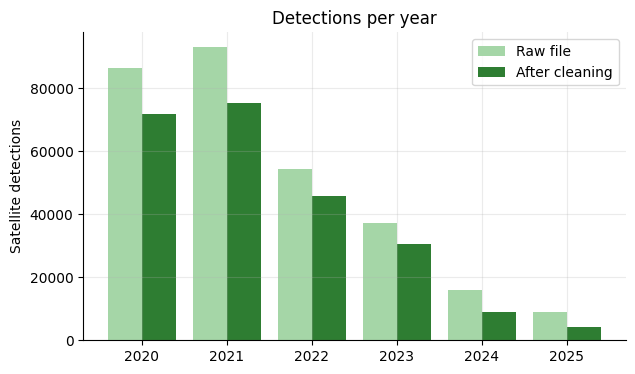

year
2020    71641
2021    75153
2022    45736
2023    30656
2024     9041
2025     4178


In [ ]:
def draw_outline(ax):
    for geom in districts.values():
        for poly in (geom.geoms if geom.geom_type == "MultiPolygon" else [geom]):
            x, y = poly.exterior.xy
            ax.plot(x, y, color="black", lw=0.3)

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
raw["year"] = raw["acq_date"].str[:4].astype(int)

# 1. detections per year (raw vs cleaned)
fig, ax = plt.subplots(figsize=(7, 4))
yr_raw, yr_clean = raw.groupby("year").size(), df.groupby("year").size()
x = np.arange(len(yr_raw))
ax.bar(x - 0.2, yr_raw.values, 0.4, label="Raw file", color="#a5d6a7")
ax.bar(x + 0.2, yr_clean.reindex(yr_raw.index).values, 0.4, label="After cleaning", color=GREEN)
ax.set_xticks(x, yr_raw.index); ax.set_ylabel("Satellite detections"); ax.legend()
ax.set_title("Detections per year")
plt.show()
print(yr_clean.to_string())

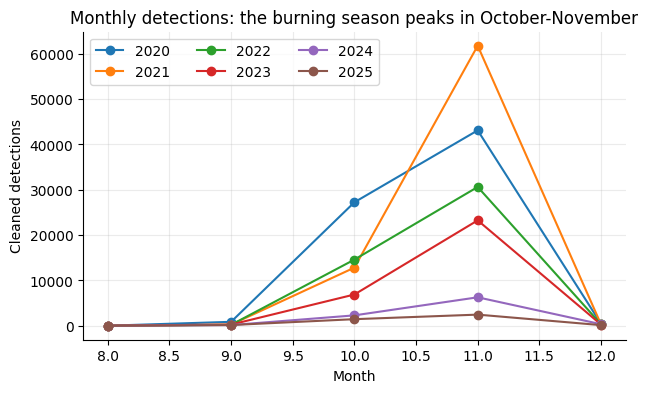

In [ ]:
# 2. monthly pattern per year
m = df.groupby(["year", "month"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4))
for yr in m.index:
    ax.plot(m.columns, m.loc[yr], marker="o", label=str(yr))
ax.set_xlabel("Month"); ax.set_ylabel("Cleaned detections"); ax.legend(ncol=3)
ax.set_title("Monthly detections: the burning season peaks in October-November")
plt.show()

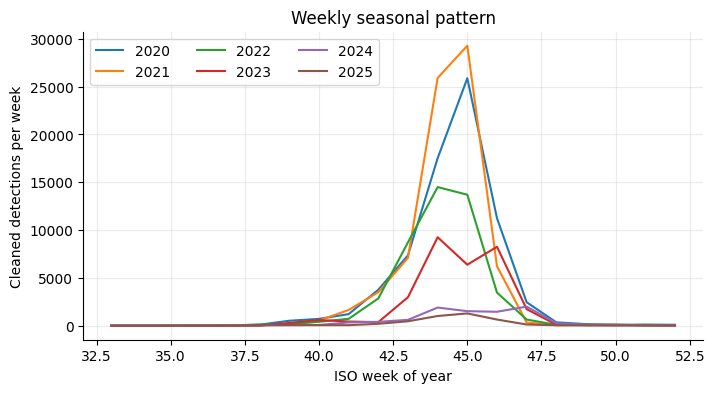

In [ ]:
# 3. weekly curves
df["iso_week"] = df["date"].dt.isocalendar().week.astype(int)
w = df.groupby(["year", "iso_week"]).size().unstack(fill_value=0)
w = w.loc[:, (w.columns >= 33) & (w.columns <= 52)]
fig, ax = plt.subplots(figsize=(8, 4))
for yr in w.index:
    ax.plot(w.columns, w.loc[yr], label=str(yr))
ax.set_xlabel("ISO week of year"); ax.set_ylabel("Cleaned detections per week"); ax.legend(ncol=3)
ax.set_title("Weekly seasonal pattern")
plt.show()

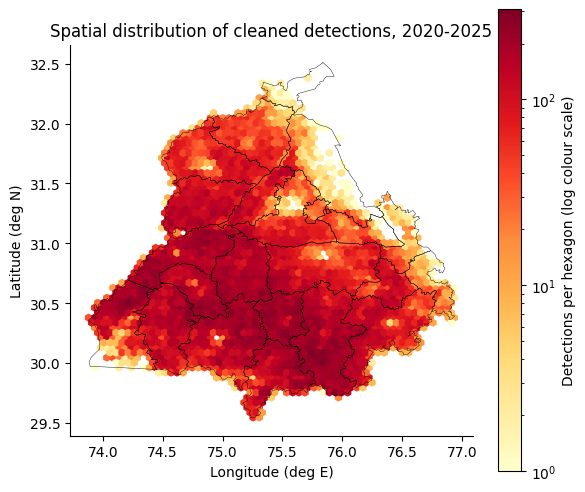

In [ ]:
# 4. where are the detections? (hexagon map)
fig, ax = plt.subplots(figsize=(6.5, 6))
hb = ax.hexbin(df.longitude, df.latitude, gridsize=60, bins="log", cmap="YlOrRd", mincnt=1)
fig.colorbar(hb, label="Detections per hexagon (log colour scale)")
draw_outline(ax)
ax.set_aspect("equal"); ax.set_xlabel("Longitude (deg E)"); ax.set_ylabel("Latitude (deg N)")
ax.set_title("Spatial distribution of cleaned detections, 2020-2025"); ax.grid(False)
plt.show()

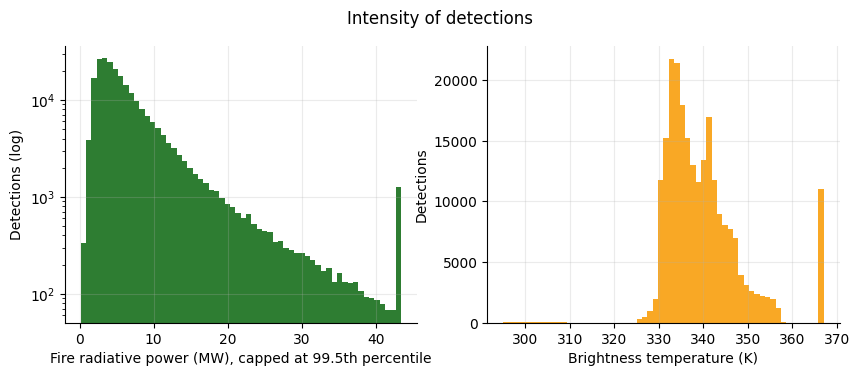

             frp  brightness
count  236405.00   236405.00
mean        7.14      339.89
std         6.83        8.68
min         0.14      295.03
25%         3.34      333.73
50%         5.12      337.99
75%         8.40      343.40
max       296.83      367.00


In [ ]:
# 5. intensity: FRP and brightness
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
axs[0].hist(df.frp.clip(upper=df.frp.quantile(0.995)), bins=60, color=GREEN)
axs[0].set_yscale("log"); axs[0].set_xlabel("Fire radiative power (MW), capped at 99.5th percentile"); axs[0].set_ylabel("Detections (log)")
axs[1].hist(df.brightness, bins=60, color=AMBER)
axs[1].set_xlabel("Brightness temperature (K)"); axs[1].set_ylabel("Detections")
plt.suptitle("Intensity of detections"); plt.show()
print(df[["frp", "brightness"]].describe().round(2))

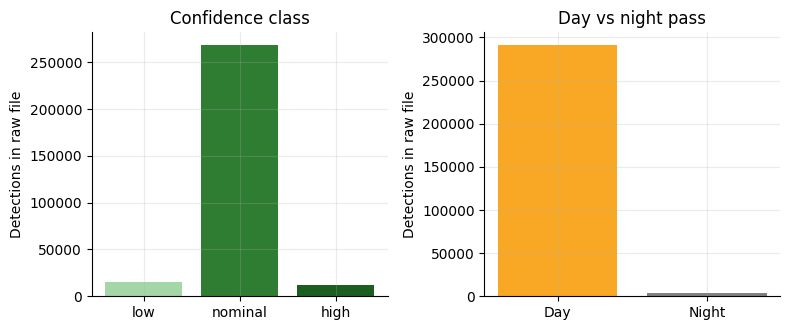

Night detections: 1.5% of the raw file


In [ ]:
# 6. confidence and day/night (computed on the RAW file, before cleaning)
fig, axs = plt.subplots(1, 2, figsize=(8, 3.4))
c = raw["confidence"].value_counts().reindex(["l", "n", "h"])
axs[0].bar(["low", "nominal", "high"], c.values, color=["#a5d6a7", GREEN, DARK]); axs[0].set_title("Confidence class")
d = raw["daynight"].value_counts().reindex(["D", "N"])
axs[1].bar(["Day", "Night"], d.values, color=[AMBER, "grey"]); axs[1].set_title("Day vs night pass")
for a in axs: a.set_ylabel("Detections in raw file")
plt.tight_layout(); plt.show()
print(f"Night detections: {d['N'] / d.sum():.1%} of the raw file")

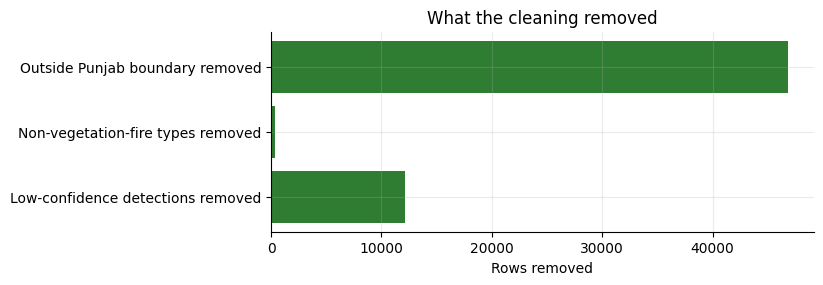

In [ ]:
# 7. data-quality chart: rows removed at each step
q = pd.DataFrame(steps)
q = q[q.Removed > 0]
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(q.Step[::-1], q.Removed[::-1], color=GREEN); ax.set_xlabel("Rows removed")
ax.set_title("What the cleaning removed"); plt.show()

**What the EDA shows (read these from your own charts):**
- Detections are heavily concentrated in **October and November**, which matches paddy-straw burning after harvest.
- The number of detections **falls strongly from 2020 to 2025**. We do not claim a cause: it may reflect real change, but satellite coverage/overpass changes can also play a part.
- Detections are spread across the whole central Punjab paddy belt, thinner in the north-east hills and the south-west.
- Almost all detections come from daytime passes (see the printed percentage above).

---
# Part 4 · Build the weekly 5 km grid dataset *(Unit I: preparing data for prediction)*

Machine-learning models need a table where **each row is one example** and the **last column is what we want to predict**.

**One row = one 5 km × 5 km cell in one week.** We predict the next week from what we know at the end of this week.

How we build it:
1. Convert latitude/longitude to **metres** (UTM zone 43N) so every cell really is 5 km × 5 km. (Degrees of longitude and latitude are not equal distances.)
2. Keep cells whose **centre lies inside a Punjab district**.
3. Count detections per cell per week (weeks start on Monday). Weeks with no detection get **0**.
4. Add features from the **past only** (lags, cumulative counts, neighbouring cells).
5. Add the **target**: next week's count (`target_count`) and whether it is above zero (`target_fire`).

> **Leakage rule:** a row for week *t* may only use information from week *t* and earlier. Targets come from week *t+1*.

In [ ]:
SIZE = 5000                                   # 5 km in metres
to_utm = Transformer.from_crs("EPSG:4326", "EPSG:32643", always_xy=True)
to_ll = Transformer.from_crs("EPSG:32643", "EPSG:4326", always_xy=True)

# candidate cells covering the bounding box of Punjab
minx = min(g.bounds[0] for g in districts.values()); miny = min(g.bounds[1] for g in districts.values())
maxx = max(g.bounds[2] for g in districts.values()); maxy = max(g.bounds[3] for g in districts.values())
ux, uy = to_utm.transform([minx, maxx, minx, maxx], [miny, miny, maxy, maxy])
ix_min, ix_max = int(np.floor(min(ux) / SIZE)) - 1, int(np.ceil(max(ux) / SIZE)) + 1
iy_min, iy_max = int(np.floor(min(uy) / SIZE)) - 1, int(np.ceil(max(uy) / SIZE)) + 1
NX, NY = ix_max - ix_min + 1, iy_max - iy_min + 1

gx, gy = np.meshgrid(np.arange(ix_min, ix_max + 1), np.arange(iy_min, iy_max + 1), indexing="ij")
cells = pd.DataFrame({"ix": gx.ravel(), "iy": gy.ravel()})
lon_c, lat_c = to_ll.transform((cells.ix.values + 0.5) * SIZE, (cells.iy.values + 0.5) * SIZE)
cells["lon"], cells["lat"] = lon_c, lat_c
cells["district"] = assign_district(cells.lon.values, cells.lat.values)
cells = cells[cells.district.notna()].reset_index(drop=True)      # keep cells whose centre is inside Punjab
cells["cell_id"] = cells.index
cells["gx"], cells["gy"] = cells.ix - ix_min, cells.iy - iy_min   # position inside the 2-D array used later
print(f"Grid cells inside Punjab: {len(cells):,}  (each {SIZE // 1000} km x {SIZE // 1000} km)")
print("Districts covered:", cells.district.nunique())

# put every detection into a cell
x, y = to_utm.transform(df.longitude.values, df.latitude.values)
df["ix"], df["iy"] = np.floor(x / SIZE).astype(int), np.floor(y / SIZE).astype(int)
fires = df.merge(cells[["ix", "iy", "cell_id"]], on=["ix", "iy"], how="inner")
print(f"Detections inside Punjab: {len(df):,} | placed in a grid cell: {len(fires):,} "
      f"(the rest sit in border cells whose centre is outside Punjab)")

Grid cells inside Punjab: 2,014  (each 5 km x 5 km)
Districts covered: 22


Detections inside Punjab: 236,405 | placed in a grid cell: 233,762 (the rest sit in border cells whose centre is outside Punjab)


In [ ]:
# weekly counts per cell
fires["week_start"] = fires["date"] - pd.to_timedelta(fires["date"].dt.dayofweek, unit="D")
weekly = fires.groupby(["cell_id", "week_start"]).agg(fire_count=("frp", "size"), frp_sum=("frp", "sum")).reset_index()

# only use years whose raw data covers the whole 25 Aug - 10 Dec window (so a zero really means 'no detection')
dates = pd.to_datetime(raw["acq_date"])
span = dates.groupby(dates.dt.year).agg(["min", "max"])
years_ok = [int(y) for y in span.index
            if span.loc[y, "min"] <= pd.Timestamp(y, 8, 25) and span.loc[y, "max"] >= pd.Timestamp(y, 12, 10)]
print("Years with full coverage:", years_ok)

weeks = []
for yr in years_ok:
    start, end = pd.Timestamp(yr, 8, 25), pd.Timestamp(yr, 12, 10)
    d = pd.date_range(start, end)
    ws = pd.Series(d - pd.to_timedelta(d.dayofweek, unit="D")).drop_duplicates()
    weeks += list(ws[(ws >= start) & (ws + pd.Timedelta(days=6) <= end)])
weeks = pd.DatetimeIndex(sorted(set(weeks)))

# every cell x every week (zeros where nothing was detected)
panel = pd.MultiIndex.from_product([cells.cell_id, weeks], names=["cell_id", "week_start"]).to_frame(index=False)
panel = panel.merge(weekly, on=["cell_id", "week_start"], how="left").fillna({"fire_count": 0, "frp_sum": 0.0})
panel = panel.merge(cells, on="cell_id").sort_values(["cell_id", "week_start"]).reset_index(drop=True)
panel["year"] = panel.week_start.dt.year
panel["week_of_year"] = panel.week_start.dt.isocalendar().week.astype(int)
print("Panel (all cells x all weeks):", panel.shape)
panel.head()

Years with full coverage: [2020, 2021, 2022, 2023, 2024, 2025]
Panel (all cells x all weeks): (175218, 13)


,cell_id,week_start,fire_count,frp_sum,ix,iy,lon,lat,district,gx,gy,year,week_of_year
0,0,2020-08-31,0.0,0.0,79,663,73.937448,29.984113,Fazilka,2,11,2020,36
1,0,2020-09-07,0.0,0.0,79,663,73.937448,29.984113,Fazilka,2,11,2020,37
2,0,2020-09-14,0.0,0.0,79,663,73.937448,29.984113,Fazilka,2,11,2020,38
3,0,2020-09-21,0.0,0.0,79,663,73.937448,29.984113,Fazilka,2,11,2020,39
4,0,2020-09-28,0.0,0.0,79,663,73.937448,29.984113,Fazilka,2,11,2020,40


In [ ]:
# --- features from neighbouring cells (same week only) ---
k3 = np.ones((3, 3)); k3[1, 1] = 0            # the 8 touching cells
k5 = np.ones((5, 5)); k5[1:4, 1:4] = 0        # the outer ring of 16 cells
nb1 = pd.Series(0.0, index=panel.index)
nb2 = pd.Series(0.0, index=panel.index)
for wk, g in panel.groupby("week_start"):
    grid = np.zeros((NX, NY))
    grid[g.gx.values, g.gy.values] = g.fire_count.values
    nb1.loc[g.index] = ndimage.convolve(grid, k3, mode="constant")[g.gx.values, g.gy.values]
    nb2.loc[g.index] = ndimage.convolve(grid, k5, mode="constant")[g.gx.values, g.gy.values]
panel["nb1_count"], panel["nb2_count"] = nb1, nb2
panel["district_fire_count"] = panel.groupby(["district", "week_start"]).fire_count.transform("sum")

# --- features from the past of the same cell (inside one year, so seasons never mix) ---
g = panel.groupby(["cell_id", "year"])
panel["fires_lag1"] = g.fire_count.shift(1)             # detections 1 week ago
panel["fires_lag2"] = g.fire_count.shift(2)
panel["fires_lag3"] = g.fire_count.shift(3)
panel["fires_roll3"] = panel.fire_count + panel.fires_lag1 + panel.fires_lag2     # this week + 2 previous
panel["season_cum_count"] = g.fire_count.cumsum()       # detections since 25 Aug

# --- same week, previous year ---
prev = panel[["cell_id", "year", "week_of_year", "fire_count"]].copy()
prev["year"] += 1
prev = prev.rename(columns={"fire_count": "prev_year_same_week"})
panel = panel.merge(prev, on=["cell_id", "year", "week_of_year"], how="left")
panel["has_prev_year"] = panel.prev_year_same_week.notna().astype(int)    # 0 for the first year (no earlier data)
panel["prev_year_same_week"] = panel.prev_year_same_week.fillna(0)
panel = panel.sort_values(["cell_id", "week_start"]).reset_index(drop=True)
print("Fire-only features ready. Columns:", panel.shape[1])

Fire-only features ready. Columns: 23


### Weather data (Open-Meteo) — optional, needs internet

Weather helps answer objective **O2** (are rain, wind and temperature related to fires?).
The next cell downloads **real historical daily weather** for each district centre from the free Open-Meteo archive (no API key). If there is no internet, it prints a clear message and the project continues in **fire-only mode**. Nothing is invented or filled in.

Docs: https://open-meteo.com/en/docs/historical-weather-api

In [ ]:
import os, time
import requests

weather_cols = []
WEATHER_FILE = "data/raw/weather_daily.csv"
VARS = "temperature_2m_mean,precipitation_sum,wind_speed_10m_max,et0_fao_evapotranspiration,shortwave_radiation_sum"

if not os.path.exists(WEATHER_FILE):
    frames, ok = [], True
    for name, geom in districts.items():
        c = geom.centroid
        params = {"latitude": round(c.y, 4), "longitude": round(c.x, 4), "start_date": "2020-08-01",
                  "end_date": "2025-12-31", "daily": VARS, "timezone": "Asia/Kolkata"}
        try:
            r = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=60)
            r.raise_for_status()
            d = pd.DataFrame(r.json()["daily"]); d.insert(0, "district", name); frames.append(d)
            print("downloaded:", name)
            time.sleep(1.5)
        except Exception as e:
            print("Weather download failed:", str(e)[:120]); ok = False; break
    if ok and frames:
        pd.concat(frames).to_csv(WEATHER_FILE, index=False)
        print("Saved", WEATHER_FILE)

if os.path.exists(WEATHER_FILE):
    wx = pd.read_csv(WEATHER_FILE, parse_dates=["time"])
    wx["week_start"] = wx.time - pd.to_timedelta(wx.time.dt.dayofweek, unit="D")
    wk = wx.groupby(["district", "week_start"]).agg(temp_mean=("temperature_2m_mean", "mean"), rain_sum=("precipitation_sum", "sum"),
                                                    wind_max=("wind_speed_10m_max", "max"), et0_sum=("et0_fao_evapotranspiration", "sum"),
                                                    radiation_sum=("shortwave_radiation_sum", "sum")).reset_index()
    wk["rain_lag1"] = wk.sort_values("week_start").groupby("district").rain_sum.shift(1)
    panel = panel.merge(wk, on=["district", "week_start"], how="left")
    weather_cols = ["temp_mean", "rain_sum", "wind_max", "et0_sum", "radiation_sum", "rain_lag1"]
    print("Weather merged. Missing values:", panel[weather_cols].isna().mean().max().round(4))
else:
    print("\nFIRE-ONLY MODE: weather is PENDING (no internet / download failed).")
    print("Connect to the internet and run this cell again to add weather.")

Weather download failed: HTTPSConnectionPool(host='archive-api.open-meteo.com', port=443): Max retries exceeded with url: /v1/archive?latitude=31

FIRE-ONLY MODE: weather is PENDING (no internet / download failed).
Connect to the internet and run this cell again to add weather.


In [ ]:
# --- targets: what happens NEXT week (used only as labels) ---
g = panel.groupby(["cell_id", "year"])
panel["target_count"] = g.fire_count.shift(-1)
panel["target_fire"] = (panel.target_count > 0).astype(float).where(panel.target_count.notna())

# keep the burning season only: weeks starting 15 Sep - 30 Nov
md_ = panel.week_start.dt.month * 100 + panel.week_start.dt.day
data = panel[(md_ >= 915) & (md_ <= 1130)].dropna(subset=["target_count", "fires_lag3"]).copy()
data["target_count"] = data.target_count.astype(int)
data["target_fire"] = data.target_fire.astype(int)
data = data.reset_index(drop=True)

features = ["fire_count", "frp_sum", "fires_lag1", "fires_lag2", "fires_lag3", "fires_roll3", "season_cum_count",
            "nb1_count", "nb2_count", "district_fire_count", "prev_year_same_week", "has_prev_year",
            "week_of_year", "lat", "lon"] + weather_cols

os.makedirs("data/processed", exist_ok=True)
data.to_csv("data/processed/weekly_grid_dataset.csv", index=False)
print("Saved data/processed/weekly_grid_dataset.csv")
print(f"Rows: {len(data):,} | cells: {data.cell_id.nunique():,} | weeks: {data.week_start.nunique()} | features: {len(features)}")
print(f"Missing values in model features: {int(data[features].isna().sum().sum())}")
print("\nShare of cell-weeks with a detection NEXT week, by year:")
print((data.groupby('year').target_fire.mean() * 100).round(1).astype(str) + " %")
data[features + ["target_count", "target_fire"]].head()

Saved data/processed/weekly_grid_dataset.csv
Rows: 126,882 | cells: 2,014 | weeks: 63 | features: 15
Missing values in model features: 0

Share of cell-weeks with a detection NEXT week, by year:
year
2020    41.2 %
2021    40.6 %
2022    34.0 %
2023    29.0 %
2024    18.5 %
2025    10.3 %
Name: target_fire, dtype: str


,fire_count,frp_sum,fires_lag1,fires_lag2,fires_lag3,fires_roll3,season_cum_count,nb1_count,nb2_count,district_fire_count,prev_year_same_week,has_prev_year,week_of_year,lat,lon,target_count,target_fire
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,39,29.984113,73.937448,0,0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,40,29.984113,73.937448,0,0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,13.0,0.0,0,41,29.984113,73.937448,0,0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.0,138.0,0.0,0,42,29.984113,73.937448,0,0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,262.0,0.0,0,43,29.984113,73.937448,0,0


**What each feature means**

| Feature | Meaning |
|---|---|
| `fire_count`, `frp_sum` | detections and total fire power in this cell **this week** |
| `fires_lag1/2/3` | detections 1, 2, 3 weeks ago |
| `fires_roll3` | detections this week + the 2 weeks before |
| `season_cum_count` | detections since 25 Aug |
| `nb1_count`, `nb2_count` | detections this week in the 8 touching cells / the outer ring of 16 cells |
| `district_fire_count` | detections in the whole district this week |
| `prev_year_same_week`, `has_prev_year` | same week last year (0 and flag = 0 for 2020, which has no earlier year) |
| `week_of_year`, `lat`, `lon` | time of season and place |
| weather columns | rain, temperature, wind, evaporation, radiation (when downloaded) |

**Targets:** `target_count` = detections next week (regression) · `target_fire` = 1 if next week has at least one detection (classification).

A zero means *no detection*; it can also hide a real fire under cloud. This is a limitation of all satellite data.

---
# Part 5 · Statistical analysis and correlations *(Unit II)*

Charts show patterns; **statistical tests** tell us whether a pattern is likely to be real or just chance.

In [ ]:
# 1. Spearman correlation of every feature with next week's count
rows = []
for f in features:
    rho, p = stats.spearmanr(data[f], data.target_count)
    rows.append({"Feature": f, "Spearman rho": rho, "p-value": p})
corr = pd.DataFrame(rows).sort_values("Spearman rho", key=abs, ascending=False).reset_index(drop=True)
print("Spearman correlation with next-week detections (rank-based, works for skewed counts):")
corr.style.format({"Spearman rho": "{:.3f}", "p-value": lambda v: fmt_p(v)})

Spearman correlation with next-week detections (rank-based, works for skewed counts):


,Feature,Spearman rho,p-value
0,nb1_count,0.601,< 1e-300 (practically zero)
1,nb2_count,0.590,< 1e-300 (practically zero)
2,frp_sum,0.571,< 1e-300 (practically zero)
3,fire_count,0.570,< 1e-300 (practically zero)
4,district_fire_count,0.570,< 1e-300 (practically zero)
5,prev_year_same_week,0.420,< 1e-300 (practically zero)
6,fires_roll3,0.412,< 1e-300 (practically zero)
7,season_cum_count,0.331,< 1e-300 (practically zero)
8,fires_lag1,0.297,< 1e-300 (practically zero)
9,has_prev_year,-0.136,< 1e-300 (practically zero)


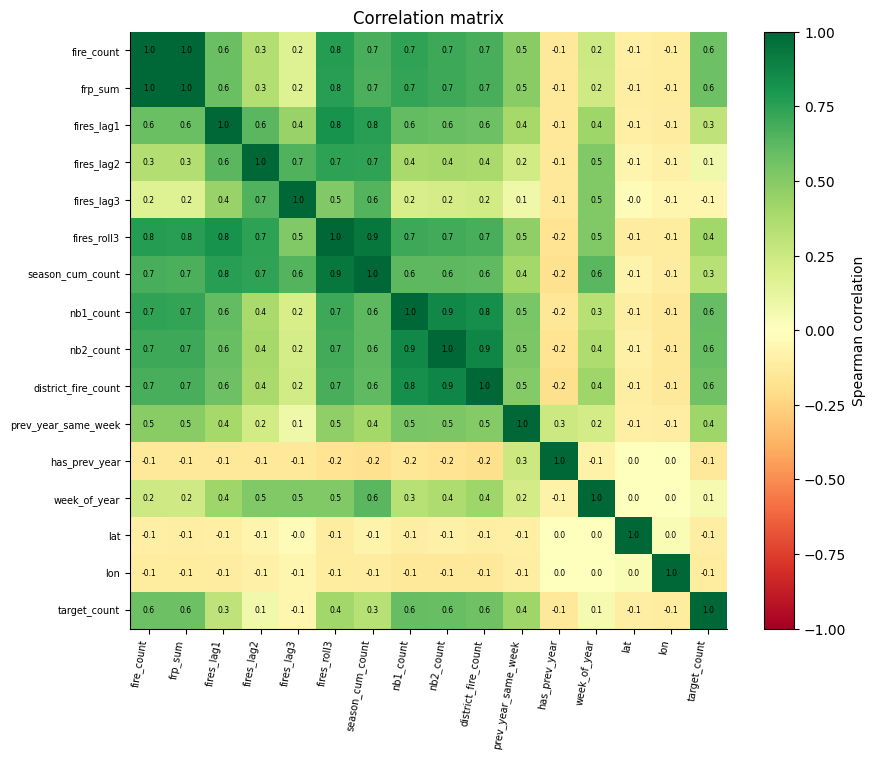

In [ ]:
# 2. correlation heatmap
cols = features + ["target_count"]
cm = data[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cm.values, cmap="RdYlGn", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(cols)), cols, rotation=80, ha="right", fontsize=7); ax.set_yticks(range(len(cols)), cols, fontsize=7)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{cm.values[i, j]:.1f}", ha="center", va="center", fontsize=5.5)
fig.colorbar(im, label="Spearman correlation"); ax.set_title("Correlation matrix"); plt.tight_layout(); plt.show()

In [ ]:
# 3. Mann-Whitney U test: are detections per cell-week different in 2020-2022 vs 2024-2025?
early = data[data.year.isin([2020, 2021, 2022])].fire_count
late = data[data.year.isin([2024, 2025])].fire_count
u, p = stats.mannwhitneyu(early, late)
print(f"Mean detections per cell-week: 2020-22 = {early.mean():.2f} | 2024-25 = {late.mean():.2f}")
print(f"Mann-Whitney U p-value = {fmt_p(p)}  ->  {'significant difference' if p < 0.05 else 'no significant difference'} (alpha = 0.05)")

# 4. Kruskal-Wallis test: do districts differ in activity?
groups = [g.fire_count.values for _, g in data.groupby("district")]
h, p = stats.kruskal(*groups)
print(f"\nKruskal-Wallis across {len(groups)} districts: H = {h:.1f}, p-value = {fmt_p(p)}  ->  "
      f"{'districts differ' if p < 0.05 else 'no evidence of difference'}")

# 5. Chi-square test: does a detection this week go with a detection next week?
table = pd.crosstab(data.fire_count > 0, data.target_fire)
chi2, p, dof, _ = stats.chi2_contingency(table)
print(f"\nChi-square (fire this week vs fire next week): chi2 = {chi2:.0f}, p-value = {fmt_p(p)}")
print(table.rename(index={False: "no fire this week", True: "fire this week"}, columns={0: "no fire next week", 1: "fire next week"}))

Mean detections per cell-week: 2020-22 = 3.13 | 2024-25 = 0.28
Mann-Whitney U p-value = < 1e-300 (practically zero)  ->  significant difference (alpha = 0.05)

Kruskal-Wallis across 22 districts: H = 7098.8, p-value = < 1e-300 (practically zero)  ->  districts differ

Chi-square (fire this week vs fire next week): chi2 = 31866, p-value = < 1e-300 (practically zero)
target_fire        no fire next week  fire next week
fire_count                                          
no fire this week              77959           12910
fire this week                 12837           23176


**How to read these results**
- **Spearman** close to +1 means "when this feature is high, next week's count is high". Values near 0 mean no rank-based relationship.
- **Mann–Whitney** compares two periods without assuming a normal distribution. A tiny p-value (< 0.05) means the difference is very unlikely to be chance.
- **Kruskal–Wallis** is the same idea for more than two groups (here, the districts).
- **Chi-square** tests whether "fire this week" and "fire next week" are independent. A tiny p-value says they are linked, which is exactly why past activity predicts the future.
- A statistically significant result does **not** prove cause and effect.

---
# Part 6 · Train / validation / test split and evaluation tools *(Unit II & III)*

Fire data depends on time, so we split **by time, never randomly**. A random split would put future weeks in the training set and make the scores look unrealistically good.

| Set | Years | Used for |
|---|---|---|
| **Train** | 2020, 2021, 2022 | teach the model |
| **Validation** | 2023 | choose settings and the best model |
| **Test** | 2024, 2025 | final, untouched exam |

Scaling and imputation are placed **inside** the model pipelines, so they learn only from the training rows.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer, PolynomialFeatures
from sklearn import metrics as M

train = data[data.year.isin([2020, 2021, 2022])]
val = data[data.year == 2023]
test = data[data.year.isin([2024, 2025])]
for name, part in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name:11s} {len(part):7,} rows | weeks {part.week_start.min().date()} -> {part.week_start.max().date()} | "
          f"fire next week: {part.target_fire.mean():.1%}")

def safe_log1p(x):
    return np.log1p(np.clip(x, 0, None))      # counts are heavily skewed: log1p squeezes the large values

def scaled(model):
    # log -> standardise -> model. Fitted on training rows only.
    return Pipeline([("log", FunctionTransformer(safe_log1p)), ("scale", StandardScaler()), ("model", model)])

def reg_scores(y, p):
    mse = M.mean_squared_error(y, p)
    return {"MAE": M.mean_absolute_error(y, p), "MSE": mse, "RMSE": np.sqrt(mse), "R2": M.r2_score(y, p)}

Train        60,420 rows | weeks 2020-09-21 -> 2022-11-21 | fire next week: 38.6%
Validation   22,154 rows | weeks 2023-09-18 -> 2023-11-27 | fire next week: 29.0%
Test         44,308 rows | weeks 2024-09-16 -> 2025-11-24 | fire next week: 14.4%


---
# Part 7 · Regression: predict next week's **number** of detections *(Practical 3, Unit II, CO2)*

Target: `target_count`. We compare:
- **Baselines** (very simple rules a model must beat): "next week = this week", "next week = training average", "next week = same week last year".
- **Simple linear regression:** one input (`fire_count`).
- **Multiple linear regression:** all inputs.
- **Polynomial regression:** squared and interaction terms of the 4 strongest inputs.
- **Ridge regression:** linear regression with a penalty that shrinks large coefficients (reduces overfitting).

Metrics: **MAE** (average error), **MSE**, **RMSE** (error in detections, punishes big mistakes), **R²** (1 = perfect, 0 = as good as predicting the average, negative = worse than the average).

In [ ]:
import statsmodels.api as sm

# Ordinary Least Squares (OLS) for the simple regression: the full statistical summary
ols = sm.OLS(train.target_count, sm.add_constant(train[["fire_count"]])).fit()
print(ols.summary().tables[1])
print(f"\nR-squared on training data: {ols.rsquared:.3f}")
print("Reading: each extra detection this week adds about "
      f"{ols.params['fire_count']:.2f} detections next week (p-value {fmt_p(ols.pvalues['fire_count'])}).")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.6171      0.028     58.325      0.000       1.563       1.671
fire_count     0.4812      0.004    135.003      0.000       0.474       0.488

R-squared on training data: 0.232
Reading: each extra detection this week adds about 0.48 detections next week (p-value < 1e-300 (practically zero)).


In [ ]:
from sklearn.linear_model import LinearRegression, Ridge

reg_rows, reg_preds = [], {}

def add_reg(name, model, cols):
    model.fit(train[cols], train.target_count)
    row = {"Model": name}
    for split, part in [("Val", val), ("Test", test)]:
        p = model.predict(part[cols])
        s = reg_scores(part.target_count, p)
        row.update({f"{split} MAE": s["MAE"], f"{split} RMSE": s["RMSE"], f"{split} R2": s["R2"]})
        if split == "Test":
            reg_preds[name] = p
    reg_rows.append(row)
    return model

def add_baseline(name, fn):
    row = {"Model": "Baseline: " + name}
    for split, part in [("Val", val), ("Test", test)]:
        s = reg_scores(part.target_count, fn(part))
        row.update({f"{split} MAE": s["MAE"], f"{split} RMSE": s["RMSE"], f"{split} R2": s["R2"]})
        if split == "Test":
            reg_preds["Baseline: " + name] = np.asarray(fn(part), dtype=float)
    reg_rows.append(row)

add_baseline("same as this week", lambda d: d.fire_count.values)
add_baseline("training average", lambda d: np.full(len(d), train.target_count.mean()))
add_baseline("same week last year", lambda d: np.where(d.has_prev_year == 1, d.prev_year_same_week, train.target_count.mean()))

add_reg("Simple Linear Regression", LinearRegression(), ["fire_count"])
add_reg("Multiple Linear Regression", scaled(LinearRegression()), features)
top4 = ["fire_count", "fires_lag1", "nb1_count", "district_fire_count"]
poly = Pipeline([("log", FunctionTransformer(safe_log1p)), ("scale", StandardScaler()),
                 ("poly", PolynomialFeatures(2, include_bias=False)), ("model", LinearRegression())])
add_reg("Polynomial Regression (degree 2)", poly, top4)
add_reg("Ridge Regression", scaled(Ridge(alpha=10.0)), features)

reg_table = pd.DataFrame(reg_rows)
reg_table.style.format({c: "{:.3f}" for c in reg_table.columns if c != "Model"})

,Model,Val MAE,Val RMSE,Val R2,Test MAE,Test RMSE,Test R2
0,Baseline: same as this week,1.540,3.694,-0.143,0.401,1.098,-0.474
1,Baseline: training average,3.161,3.878,-0.260,2.918,2.982,-9.865
2,Baseline: same week last year,1.494,3.718,-0.158,0.850,2.498,-6.623
3,Simple Linear Regression,2.237,3.257,0.111,1.621,1.722,-2.621
4,Multiple Linear Regression,2.436,3.785,-0.200,1.663,2.584,-7.155
5,Polynomial Regression (degree 2),1.891,3.770,-0.191,0.814,1.658,-2.360
6,Ridge Regression,2.435,3.783,-0.199,1.662,2.581,-7.141


**Important reading of the regression results:** a negative R² on the test years means the model is worse than simply predicting the test-period average. The reason is a **distribution shift**: the models learn from 2020–2022, when detections were much higher, and then face 2024–2025, when they were much lower. This is a genuine finding, not a bug. We come back to it in Part 11 (improving accuracy).

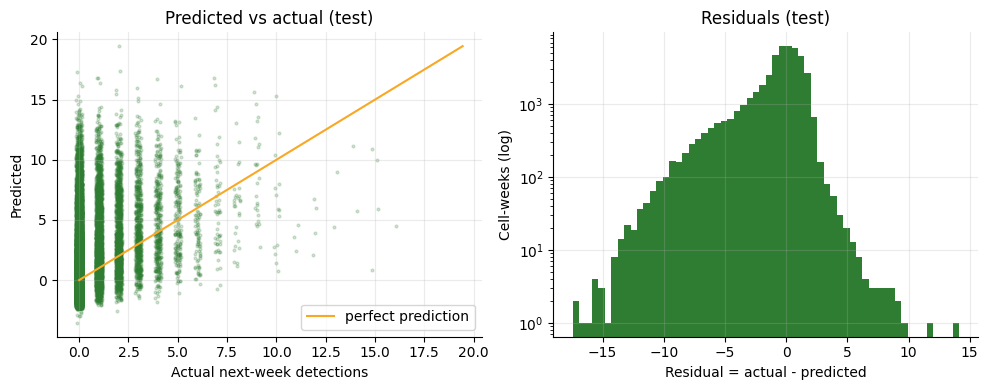

Mean residual: -0.831  (negative = the model over-predicts on average)


In [ ]:
# predicted vs actual for the multiple linear model (test period)
p = reg_preds["Multiple Linear Regression"]
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].scatter(test.target_count + np.random.default_rng(0).uniform(-.15, .15, len(test)), p, s=4, alpha=.2, color=GREEN)
lim = max(test.target_count.max(), p.max())
axs[0].plot([0, lim], [0, lim], color=AMBER, label="perfect prediction"); axs[0].legend()
axs[0].set_xlabel("Actual next-week detections"); axs[0].set_ylabel("Predicted"); axs[0].set_title("Predicted vs actual (test)")
res = test.target_count.values - p
axs[1].hist(res, bins=60, color=GREEN); axs[1].set_yscale("log")
axs[1].set_xlabel("Residual = actual - predicted"); axs[1].set_ylabel("Cell-weeks (log)"); axs[1].set_title("Residuals (test)")
plt.tight_layout(); plt.show()
print(f"Mean residual: {res.mean():.3f}  (negative = the model over-predicts on average)")

---
# Part 8 · Classification: predict **whether** a cell will have a detection next week *(Practical 4–5, Unit III, CO3)*

Target: `target_fire` (1 = at least one detection next week, 0 = none).

Models: **Logistic Regression**, **K-Nearest Neighbours**, **Naive Bayes**, **Decision Tree**, **Support Vector Machine**.

**Metrics:** Accuracy · **Log loss** (penalises confident wrong probabilities) · **ROC-AUC** (how well the model *ranks* risky cells above safe ones; 0.5 = random) · **Precision** (of predicted fires, how many were real) · **Recall** (of real fires, how many we caught) · **F1** (balance of the two) · **Confusion matrix**.

> In the test years only a minority of cell-weeks have a detection, so **accuracy is misleading**: always saying "no fire" already scores high. Focus on precision, recall, F1 and AUC.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.svm import SVC

clf_rows, clf_scores, clf_pred_test, fitted = [], {}, {}, {}

def clf_row(name, y_val, p_val, s_val, y_te, p_te, s_te, proba):
    row = {"Model": name}
    for split, y, p, s in [("Val", y_val, p_val, s_val), ("Test", y_te, p_te, s_te)]:
        row[f"{split} Accuracy"] = M.accuracy_score(y, p)
        row[f"{split} Precision"] = M.precision_score(y, p, zero_division=0)
        row[f"{split} Recall"] = M.recall_score(y, p, zero_division=0)
        row[f"{split} F1"] = M.f1_score(y, p, zero_division=0)
        row[f"{split} ROC-AUC"] = M.roc_auc_score(y, s) if s is not None else np.nan
        row[f"{split} PR-AUC"] = M.average_precision_score(y, s) if s is not None else np.nan
        row[f"{split} LogLoss"] = M.log_loss(y, np.clip(s, 1e-6, 1 - 1e-6)) if (proba and s is not None) else np.nan
    return row

def add_clf(name, model, fit_data=None):
    fd = train if fit_data is None else fit_data
    model.fit(fd[features], fd.target_fire)
    proba = hasattr(model, "predict_proba")
    out = {}
    for split, part in [("val", val), ("test", test)]:
        s = model.predict_proba(part[features])[:, 1] if proba else model.decision_function(part[features])
        p = (s >= 0.5).astype(int) if proba else (s > 0).astype(int)
        out[split] = (p, s)
    clf_rows.append(clf_row(name, val.target_fire, out["val"][0], out["val"][1], test.target_fire, out["test"][0], out["test"][1], proba))
    clf_scores[name] = (out["val"][1], out["test"][1]); clf_pred_test[name] = out["test"][0]; fitted[name] = model
    return model

def add_clf_baseline(name, fn):
    row = {"Model": "Baseline: " + name}
    pv, pt = fn(val), fn(test)
    r = clf_row("", val.target_fire, pv, pv.astype(float), test.target_fire, pt, pt.astype(float), False)
    r.pop("Model"); row.update(r)
    clf_rows.append(row); clf_pred_test["Baseline: " + name] = pt

add_clf_baseline("always 'no fire'", lambda d: np.zeros(len(d), dtype=int))
add_clf_baseline("fire this week -> fire next week", lambda d: (d.fire_count > 0).astype(int).values)
add_clf_baseline("same week last year", lambda d: ((d.prev_year_same_week > 0) & (d.has_prev_year == 1)).astype(int).values)
print("Baselines ready")

Baselines ready


In [ ]:
# Logistic regression and Naive Bayes
add_clf("Logistic Regression", scaled(LogisticRegression(max_iter=2000)))
add_clf("Naive Bayes (Gaussian)", scaled(GaussianNB()))

# KNN: choose k (number of neighbours) on the VALIDATION year, using a sample of 5,000 validation rows
val_s = val.sample(5000, random_state=42)
knn_scores = {}
for k in [5, 15, 31, 61]:
    m = scaled(KNeighborsClassifier(n_neighbors=k, n_jobs=-1)).fit(train[features], train.target_fire)
    knn_scores[k] = M.f1_score(val_s.target_fire, m.predict(val_s[features]))
print("KNN: F1 on validation sample for each k:", {k: round(v, 3) for k, v in knn_scores.items()})
best_k = max(knn_scores, key=knn_scores.get)
print("Chosen k =", best_k)
_ = add_clf(f"KNN (k={best_k})", scaled(KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)))

KNN: F1 on validation sample for each k: {5: 0.723, 15: 0.749, 31: 0.747, 61: 0.746}
Chosen k = 15


First rules learned by the tree (top 3 levels):

|--- nb1_count <= 5.50
|   |--- nb1_count <= 0.50
|   |   |--- district_fire_count <= 14.50
|   |   |   |--- nb2_count <= 0.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- nb2_count >  0.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- district_fire_count >  14.50
|   |   |   |--- week_of_year <= 43.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- week_of_year >  43.50
|   |   |   |   |--- truncated branch of depth 5
|   |--- nb1_count >  0.50
|   |   |--- week_of_year <= 43.50
|   |   |   |--- nb2_count <= 2.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- nb2_count >  2.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- week_of_year >  43.50
|   |   |   |--- week_of_year <= 44.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- week_of_year >  44.50
|   |   |   |   |--- truncated branch of depth 5
|--- nb1_count >  5.50
|   |--- 

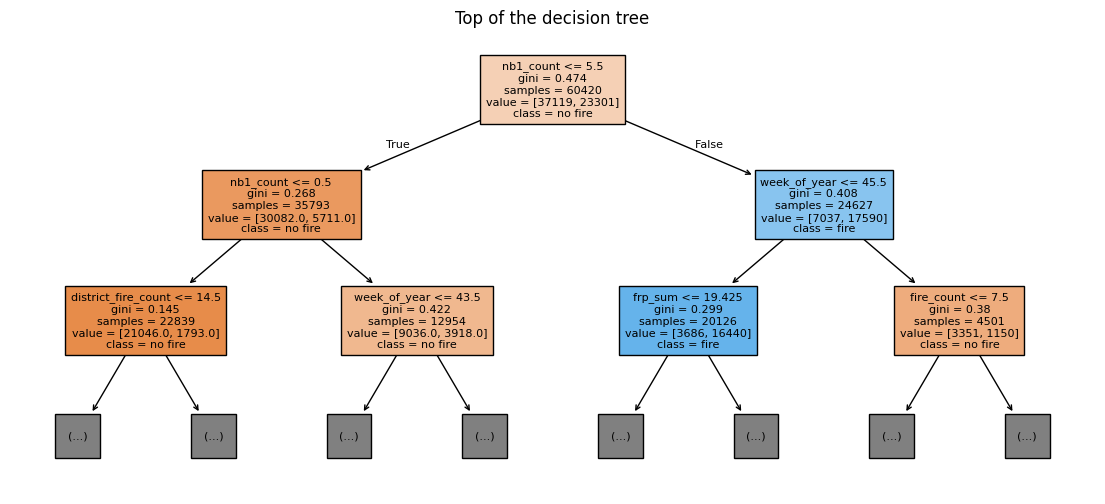

In [ ]:
# Decision Tree (+ readable rules)
tree = add_clf("Decision Tree", DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=42))
print("First rules learned by the tree (top 3 levels):\n")
print(export_text(tree, feature_names=features, max_depth=3))

fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(tree, feature_names=features, class_names=["no fire", "fire"], max_depth=2, filled=True, fontsize=8, ax=ax)
plt.title("Top of the decision tree"); plt.show()

In [ ]:
# Support Vector Machine (RBF kernel). SVMs get slow with many rows, so we train on a random sample of 6,000 training rows.
svm_sample = train.sample(6000, random_state=42)
svm = add_clf("SVM (RBF kernel)", scaled(SVC(kernel="rbf", C=1.0)), fit_data=svm_sample)
print("SVM trained on", len(svm_sample), "rows (documented limitation: SVM cost grows quickly with data size)")

SVM trained on 6000 rows (documented limitation: SVM cost grows quickly with data size)


In [ ]:
clf_table = pd.DataFrame(clf_rows)
show_cols = ["Model"] + [f"{s} {m}" for s in ["Test"] for m in ["Accuracy", "LogLoss", "ROC-AUC", "PR-AUC", "Precision", "Recall", "F1"]]
print("TEST period (2024-2025):")
clf_table[show_cols].style.format({c: "{:.3f}" for c in show_cols if c != "Model"}, na_rep="-")

TEST period (2024-2025):


,Model,Test Accuracy,Test LogLoss,Test ROC-AUC,Test PR-AUC,Test Precision,Test Recall,Test F1
0,Baseline: always 'no fire',0.856,-,0.500,0.144,0.000,0.000,0.000
1,Baseline: fire this week -> fire next week,0.823,-,0.640,0.236,0.384,0.383,0.384
2,Baseline: same week last year,0.787,-,0.700,0.265,0.353,0.578,0.438
3,Logistic Regression,0.859,0.335,0.812,0.440,0.514,0.319,0.393
4,Naive Bayes (Gaussian),0.855,0.800,0.834,0.440,0.495,0.331,0.397
5,KNN (k=15),0.820,0.619,0.825,0.427,0.417,0.639,0.505
6,Decision Tree,0.846,0.386,0.757,0.369,0.449,0.322,0.376
7,SVM (RBF kernel),0.846,-,0.832,0.461,0.470,0.540,0.503


Share of test cell-weeks with a detection next week: 14.4%
-> always predicting 'no fire' already gets 85.6% accuracy, which is why accuracy alone is misleading.



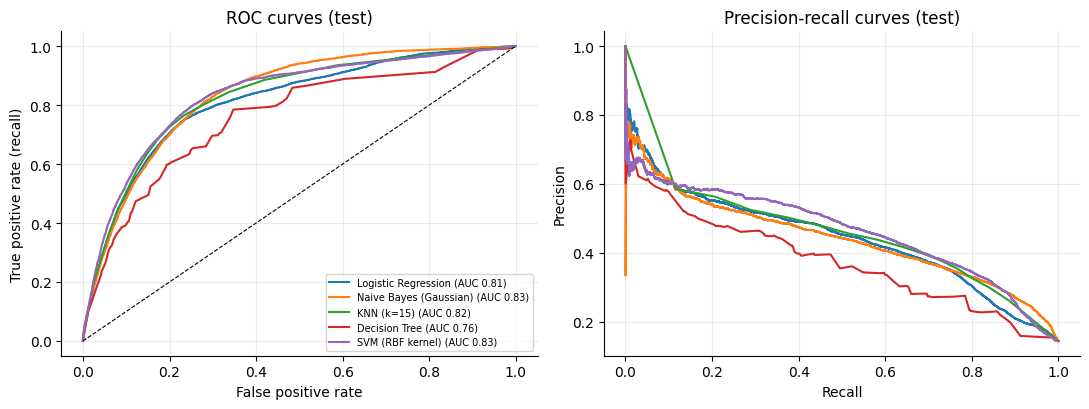

In [ ]:
rate = test.target_fire.mean()
print(f"Share of test cell-weeks with a detection next week: {rate:.1%}")
print(f"-> always predicting 'no fire' already gets {1 - rate:.1%} accuracy, which is why accuracy alone is misleading.\n")

# ROC curves
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for name, (sv, st) in clf_scores.items():
    fpr, tpr, _ = M.roc_curve(test.target_fire, st)
    axs[0].plot(fpr, tpr, label=f"{name} (AUC {M.roc_auc_score(test.target_fire, st):.2f})")
    pr, rc, _ = M.precision_recall_curve(test.target_fire, st)
    axs[1].plot(rc, pr, label=name)
axs[0].plot([0, 1], [0, 1], "k--", lw=.8); axs[0].set_xlabel("False positive rate"); axs[0].set_ylabel("True positive rate (recall)")
axs[0].set_title("ROC curves (test)"); axs[0].legend(fontsize=7)
axs[1].set_xlabel("Recall"); axs[1].set_ylabel("Precision"); axs[1].set_title("Precision-recall curves (test)")
plt.tight_layout(); plt.show()

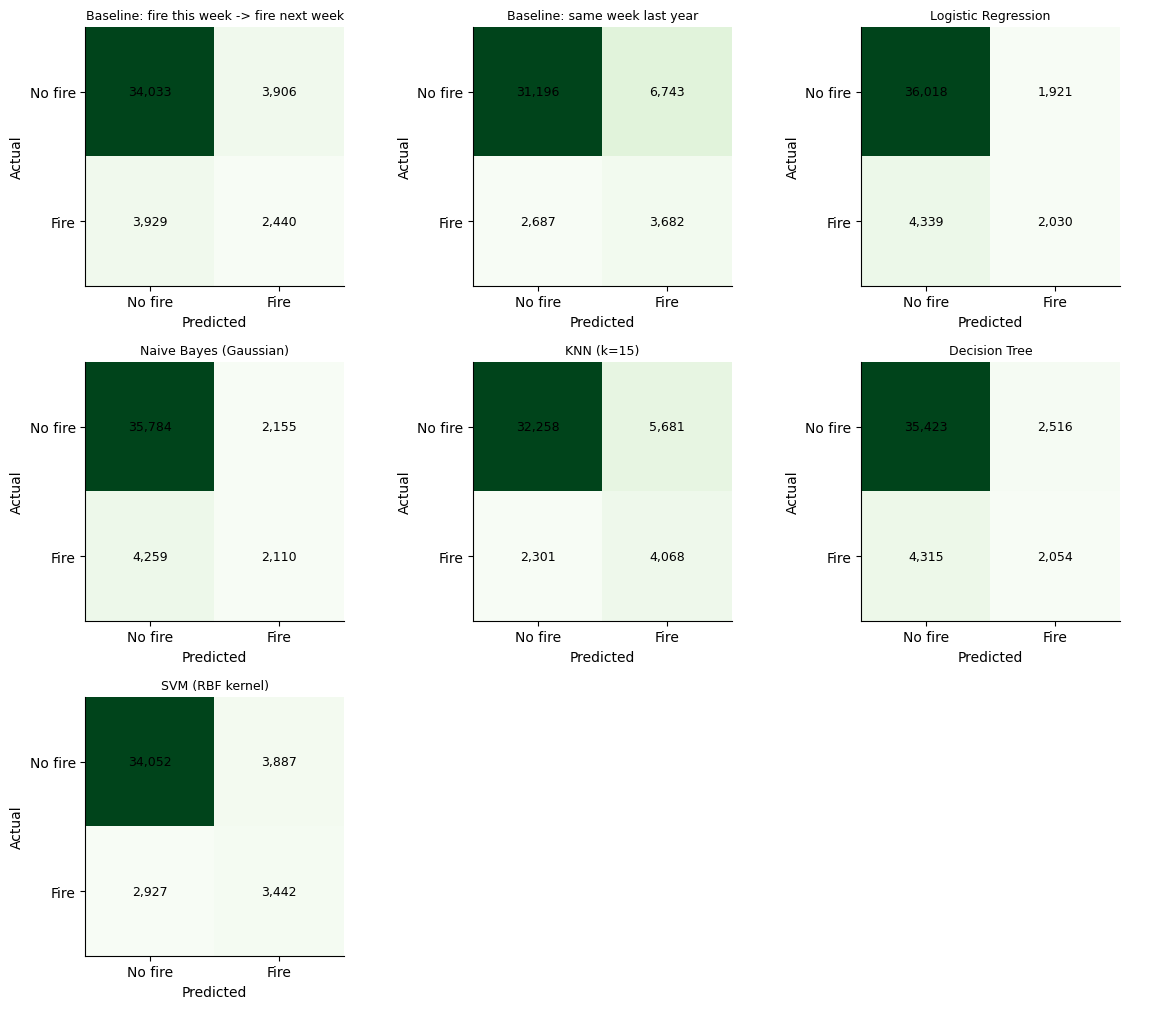

Reading: rows = actual, columns = predicted. Top-left = correct 'no fire', bottom-right = fires correctly caught.


In [ ]:
# Confusion matrices on the test period
names = [n for n in clf_pred_test if not n.startswith("Baseline: always")]
cols_n = 3; rows_n = int(np.ceil(len(names) / cols_n))
fig, axs = plt.subplots(rows_n, cols_n, figsize=(4 * cols_n, 3.4 * rows_n))
for ax, n in zip(np.ravel(axs), names):
    cmx = M.confusion_matrix(test.target_fire, clf_pred_test[n], labels=[0, 1])
    ax.imshow(cmx, cmap="Greens"); ax.grid(False)
    ax.set_xticks([0, 1], ["No fire", "Fire"]); ax.set_yticks([0, 1], ["No fire", "Fire"])
    ax.set_title(n, fontsize=9); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cmx[i, j]:,}", ha="center", va="center", fontsize=9)
for ax in np.ravel(axs)[len(names):]:
    ax.axis("off")
plt.tight_layout(); plt.show()
print("Reading: rows = actual, columns = predicted. Top-left = correct 'no fire', bottom-right = fires correctly caught.")

---
# Part 9 · Unsupervised learning: clustering and association rules *(Practical 6–7, Unit IV, CO4)*

Clustering does **not** predict anything. It finds natural groups. Here it answers a practical question:
**which parts of Punjab behave alike?**

### 9A · K-Means: grouping grid cells by their yearly fire history
Each cell is described by its total detections in each of the six years. K-Means puts similar cells in the same group.

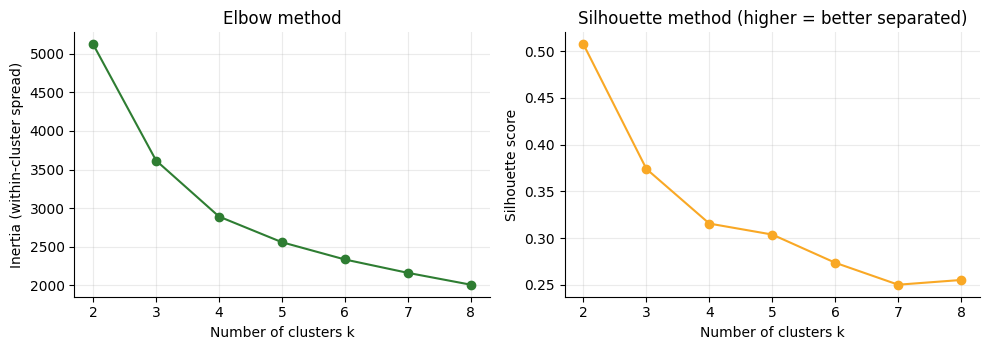

Silhouette by k: {2: 0.507, 3: 0.374, 4: 0.316, 5: 0.304, 6: 0.274, 7: 0.25, 8: 0.255}
Chosen number of clusters: 3


In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

cell_year = panel.groupby(["cell_id", "year"]).fire_count.sum().unstack(fill_value=0)
Xc = StandardScaler().fit_transform(np.log1p(cell_year.values))

ks = list(range(2, 9))
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xc)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xc, km.labels_, sample_size=1500, random_state=42))

fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
axs[0].plot(ks, inertia, marker="o", color=GREEN); axs[0].set_xlabel("Number of clusters k"); axs[0].set_ylabel("Inertia (within-cluster spread)")
axs[0].set_title("Elbow method")
axs[1].plot(ks, sil, marker="o", color=AMBER); axs[1].set_xlabel("Number of clusters k"); axs[1].set_ylabel("Silhouette score")
axs[1].set_title("Silhouette method (higher = better separated)")
plt.tight_layout(); plt.show()

# choose k with the best silhouette among k >= 3 (k = 2 would only split 'busy' from 'quiet')
cand = [(k, s) for k, s in zip(ks, sil) if k >= 3]
best_k_cl = max(cand, key=lambda t: t[1])[0]
print("Silhouette by k:", {k: round(s, 3) for k, s in zip(ks, sil)})
print("Chosen number of clusters:", best_k_cl)

In [ ]:
# The 'random initialisation trap': K-Means starts from random centres and can get stuck in a poor solution.
trap = []
for seed in range(8):
    a = KMeans(n_clusters=best_k_cl, init="random", n_init=1, random_state=seed).fit(Xc).inertia_
    b = KMeans(n_clusters=best_k_cl, init="k-means++", n_init=1, random_state=seed).fit(Xc).inertia_
    trap.append({"seed": seed, "random start": a, "k-means++ start": b})
trap = pd.DataFrame(trap).set_index("seed")
print(trap.round(1).to_string())
print(f"\nSpread (max-min) of final inertia -> random start: {trap['random start'].max() - trap['random start'].min():.1f}, "
      f"k-means++: {trap['k-means++ start'].max() - trap['k-means++ start'].min():.1f}")
spread_rand = trap["random start"].max() - trap["random start"].min()
spread_pp = trap["k-means++ start"].max() - trap["k-means++ start"].min()
if spread_rand > 1.0 and spread_rand > spread_pp:
    print("Random starts end in different solutions; k-means++ is more stable. This is the random initialisation trap.")
else:
    print("Here every start reaches almost the same solution, because the cell groups are clear-cut. The trap does not show up on this")
    print("data, but it can on harder data. k-means++ (spread-out starting centres) and several restarts (n_init=10) are the standard protection.")

      random start  k-means++ start
seed                               
0           3617.0           3617.0
1           3617.3           3617.0
2           3617.0           3617.0
3           3617.0           3617.3
4           3617.0           3616.9
5           3617.0           3617.3
6           3617.0           3617.3
7           3617.0           3617.3

Spread (max-min) of final inertia -> random start: 0.2, k-means++: 0.4
Here every start reaches almost the same solution, because the cell groups are clear-cut. The trap does not show up on this
data, but it can on harder data. k-means++ (spread-out starting centres) and several restarts (n_init=10) are the standard protection.


Average detections per cell and year in each cluster:


year,cells,2020,2021,2022,2023,2024,2025,avg 2020-25
cluster,,,,,,,,
0,600,19.7,24.6,12.7,7.3,1.8,0.9,11.2
1,343,1.6,1.8,0.7,0.4,0.3,0.2,0.8
2,1071,54.4,54.8,34.6,24.0,6.9,3.2,29.6


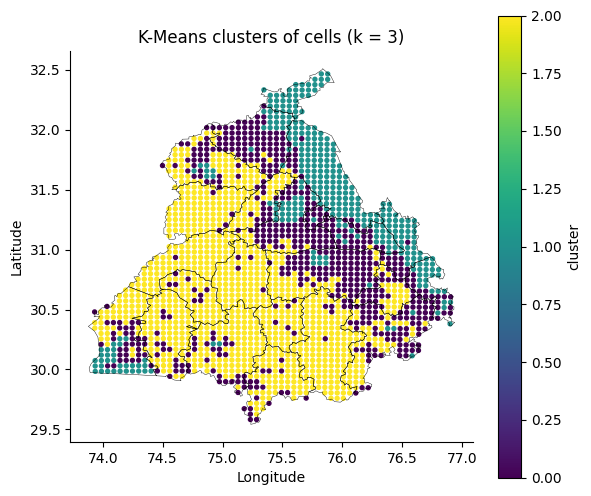

In [ ]:
final_km = KMeans(n_clusters=best_k_cl, n_init=10, random_state=42).fit(Xc)
cell_year["cluster"] = final_km.labels_
profile = cell_year.groupby("cluster").mean().round(1)
profile.insert(0, "cells", cell_year.groupby("cluster").size())
profile["avg 2020-25"] = profile[[c for c in profile.columns if isinstance(c, (int, np.integer))]].mean(axis=1).round(1)
print("Average detections per cell and year in each cluster:")
display(profile)

cmap = cells.set_index("cell_id").join(cell_year["cluster"])
fig, ax = plt.subplots(figsize=(6.5, 6))
sc = ax.scatter(cmap.lon, cmap.lat, c=cmap.cluster, cmap="viridis", s=8)
draw_outline(ax); ax.set_aspect("equal"); ax.grid(False)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_title(f"K-Means clusters of cells (k = {best_k_cl})")
fig.colorbar(sc, label="cluster"); plt.show()

**Reading the clusters:** the table shows what kind of cell each cluster is (for example *consistently high*, *high early then dropping*, *low*). The map shows where those cells are. Clusters are a description of the past, not a forecast.

### 9B · Hierarchical clustering of districts
Instead of choosing k first, hierarchical (agglomerative) clustering joins the most similar districts step by step and draws a **dendrogram**. Different **linkage** rules define "distance between two groups": *single* (closest members), *complete* (farthest members), *average*, *centroid* (distance between centres).

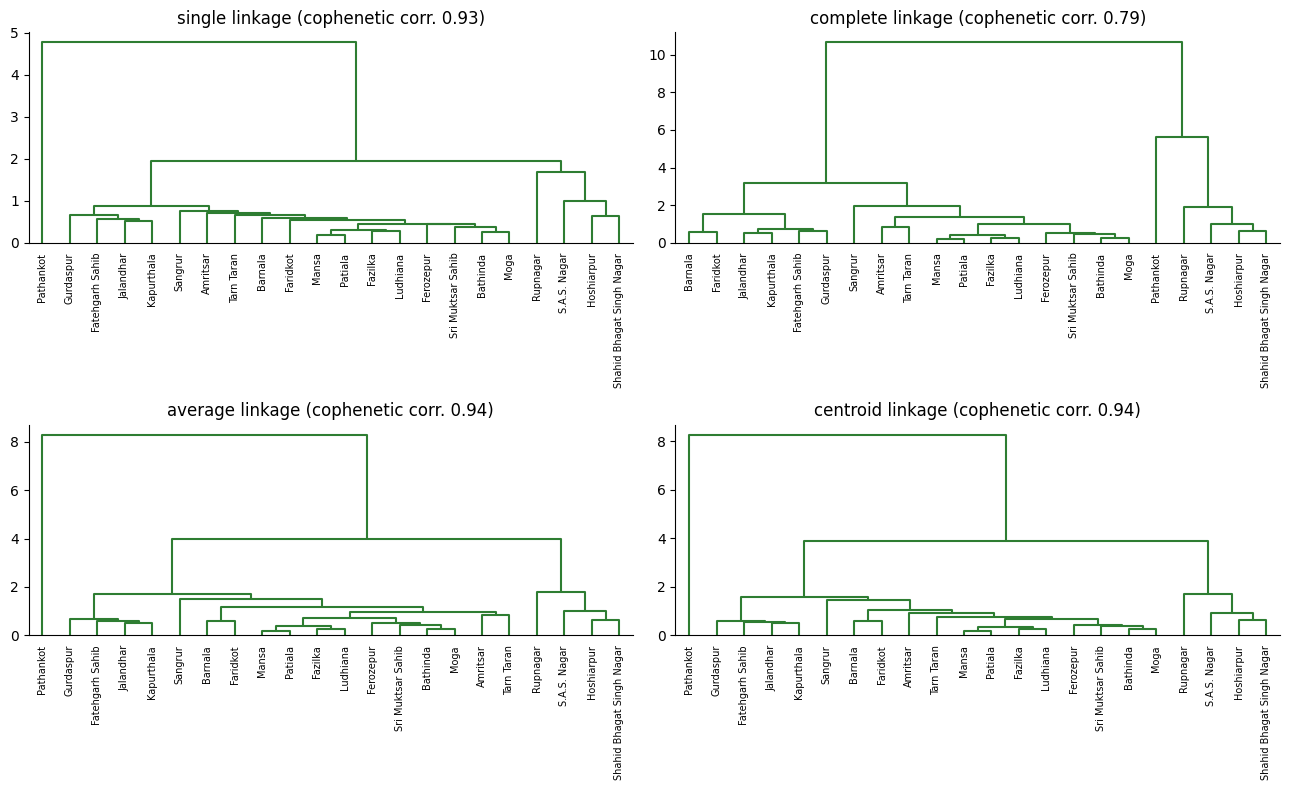

Cophenetic correlation (how faithfully the tree keeps the original distances; closer to 1 is better):
{'single': np.float64(0.929), 'complete': np.float64(0.789), 'average': np.float64(0.94), 'centroid': np.float64(0.94)}


In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist

dist_year = panel.groupby(["district", "year"]).fire_count.sum().unstack(fill_value=0)
Xd = StandardScaler().fit_transform(np.log1p(dist_year.values))

fig, axs = plt.subplots(2, 2, figsize=(13, 8))
coph = {}
for ax, method in zip(axs.ravel(), ["single", "complete", "average", "centroid"]):
    Z = linkage(Xd, method=method)
    coph[method] = cophenet(Z, pdist(Xd))[0]
    dendrogram(Z, labels=dist_year.index.tolist(), ax=ax, leaf_font_size=7, color_threshold=0, above_threshold_color=GREEN)
    ax.set_title(f"{method} linkage (cophenetic corr. {coph[method]:.2f})"); ax.tick_params(axis="x", rotation=90); ax.grid(False)
plt.tight_layout(); plt.show()
print("Cophenetic correlation (how faithfully the tree keeps the original distances; closer to 1 is better):")
print({k: round(v, 3) for k, v in coph.items()})

In [ ]:
best_link = max(coph, key=coph.get)
agg = AgglomerativeClustering(n_clusters=4, linkage="average").fit(Xd)
groups = pd.DataFrame({"district": dist_year.index, "group": agg.labels_}).join(dist_year.reset_index(drop=True))
print("Districts grouped into 4 clusters (average linkage). Columns = total detections per year:")
display(groups.sort_values(["group", "district"]).reset_index(drop=True))
print("Linkage with the best cophenetic correlation:", best_link)

Districts grouped into 4 clusters (average linkage). Columns = total detections per year:


,district,group,2020,2021,2022,2023,2024,2025
0,Amritsar,0,2377.0,1986.0,1387.0,1297.0,498.0,327.0
1,Barnala,0,4307.0,4202.0,2573.0,1950.0,214.0,61.0
2,Bathinda,0,6898.0,7400.0,4290.0,2495.0,645.0,255.0
3,Faridkot,0,3256.0,3472.0,2146.0,1435.0,388.0,84.0
4,Fatehgarh Sahib,0,1302.0,1731.0,1127.0,688.0,215.0,58.0
5,Fazilka,0,3432.0,3622.0,2660.0,1499.0,343.0,226.0
6,Ferozepur,0,5835.0,5244.0,3707.0,2831.0,896.0,369.0
7,Gurdaspur,0,1925.0,1449.0,867.0,376.0,187.0,103.0
8,Jalandhar,0,1676.0,2667.0,1243.0,904.0,176.0,102.0
9,Kapurthala,0,1485.0,1705.0,1086.0,834.0,282.0,137.0


Linkage with the best cophenetic correlation: average


### 9C · Association rules (market-basket analysis idea)
In a supermarket, a *basket* holds items bought together. Here a **basket is one day** and the **items are the districts that were "very active" that day** (above their own 75th percentile). A rule *A → B* means "when A is very active, B tends to be very active too".

- **Support** = how often A and B are both active.
- **Confidence** = of the days A is active, the share where B is also active.
- **Lift** = confidence ÷ how often B is active anyway. Lift > 1 means the pair occurs together more than chance.

> Districts that sit next to each other and share the same harvest calendar will naturally co-occur. The rules **describe patterns; they do not show cause**.

In [ ]:
season_days = df[(df.date.dt.month * 100 + df.date.dt.day >= 915) & (df.date.dt.month * 100 + df.date.dt.day <= 1130)]
daily = season_days.groupby(["date", "district"]).size().unstack(fill_value=0)
active = daily.gt(daily.quantile(0.75))             # 'very active' = above this district's own 75th percentile
A = active.values.astype(int)
n_days = len(A)
sup = A.mean(axis=0)
co = (A.T @ A) / n_days
names_d = active.columns.tolist()

rules = []
for i in range(len(names_d)):
    for j in range(len(names_d)):
        if i != j and sup[i] > 0 and sup[j] > 0 and co[i, j] > 0:
            conf = co[i, j] / sup[i]
            rules.append({"If active": names_d[i], "Then active": names_d[j], "Support": co[i, j],
                          "Confidence": conf, "Lift": conf / sup[j]})
rules = pd.DataFrame(rules)
good = rules[(rules.Support >= 0.12) & (rules.Confidence >= 0.70) & (rules.Lift >= 1.8)].sort_values("Lift", ascending=False)
print(f"Baskets (season days): {n_days} | rules tested: {len(rules)} | rules passing the filters: {len(good)}")
print("Filters: support >= 0.12, confidence >= 0.70, lift >= 1.8\n")
good.head(12).style.format({"Support": "{:.2f}", "Confidence": "{:.2f}", "Lift": "{:.2f}"})

Baskets (season days): 426 | rules tested: 462 | rules passing the filters: 237
Filters: support >= 0.12, confidence >= 0.70, lift >= 1.8



,If active,Then active,Support,Confidence,Lift
410,Shahid Bhagat Singh Nagar,Ludhiana,0.19,0.90,3.64
249,Ludhiana,Shahid Bhagat Singh Nagar,0.19,0.75,3.64
68,Faridkot,Ferozepur,0.23,0.91,3.61
129,Ferozepur,Faridkot,0.23,0.91,3.61
22,Barnala,Bathinda,0.22,0.89,3.57
43,Bathinda,Barnala,0.22,0.90,3.57
240,Ludhiana,Jalandhar,0.22,0.89,3.56
199,Jalandhar,Ludhiana,0.22,0.88,3.56
198,Jalandhar,Kapurthala,0.21,0.85,3.55
219,Kapurthala,Jalandhar,0.21,0.88,3.55


---
# Part 10 · Dimensionality reduction and neural networks *(Practical 8–9, Unit V, CO5)*

### 10A · PCA (Principal Component Analysis)
Many of our features say similar things (this week, last week, neighbours…). PCA combines them into a few new **uncorrelated components** that keep most of the information. It is useful for understanding structure and for reducing the number of inputs.

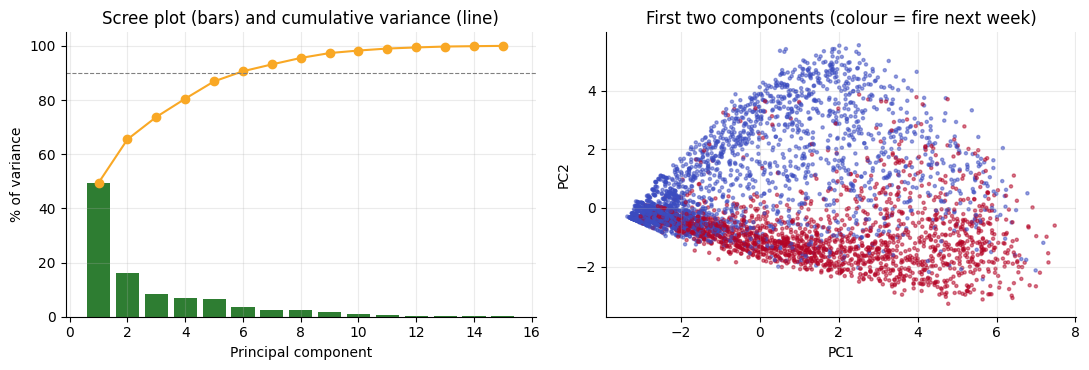

6 of 15 components keep 90% of the variance.

Features with the largest weight in PC1 and PC2:


,PC1,PC2
fires_roll3,0.350,0.126
season_cum_count,0.323,0.256
nb1_count,0.323,-0.237
nb2_count,0.319,-0.222
fires_lag1,0.313,0.097
frp_sum,0.313,-0.251
fire_count,0.312,-0.254
district_fire_count,0.301,-0.183


In [ ]:
from sklearn.decomposition import PCA

prep = Pipeline([("log", FunctionTransformer(safe_log1p)), ("scale", StandardScaler())]).fit(train[features])
Ztr = prep.transform(train[features])
pca = PCA().fit(Ztr)
cum = np.cumsum(pca.explained_variance_ratio_)
n90 = int(np.argmax(cum >= 0.90)) + 1

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].bar(range(1, len(cum) + 1), pca.explained_variance_ratio_ * 100, color=GREEN)
axs[0].plot(range(1, len(cum) + 1), cum * 100, color=AMBER, marker="o")
axs[0].axhline(90, color="grey", ls="--", lw=.8)
axs[0].set_xlabel("Principal component"); axs[0].set_ylabel("% of variance"); axs[0].set_title("Scree plot (bars) and cumulative variance (line)")
smp = train.sample(5000, random_state=1); Zs = pca.transform(prep.transform(smp[features]))
sc = axs[1].scatter(Zs[:, 0], Zs[:, 1], c=smp.target_fire, cmap="coolwarm", s=5, alpha=.5)
axs[1].set_xlabel("PC1"); axs[1].set_ylabel("PC2"); axs[1].set_title("First two components (colour = fire next week)")
plt.tight_layout(); plt.show()

print(f"{n90} of {len(features)} components keep 90% of the variance.")
load = pd.DataFrame(pca.components_[:2].T, index=features, columns=["PC1", "PC2"])
print("\nFeatures with the largest weight in PC1 and PC2:")
display(load.reindex(load.PC1.abs().sort_values(ascending=False).index).head(8).round(3))

# does a classifier lose much when it only sees the first components?
pca_lr = Pipeline([("prep", prep), ("pca", PCA(n_components=n90)), ("model", LogisticRegression(max_iter=2000))])
_ = add_clf(f"Logistic Regression on {n90} PCA components", pca_lr)

### 10B · Feedforward neural network (MLP)
A **Multi-Layer Perceptron** is layers of simple units. Each unit takes a weighted sum of the inputs and passes it through a non-linear function; training adjusts the weights step by step to reduce the error. We use scikit-learn's `MLPClassifier` and `MLPRegressor` with two hidden layers (32 and 16 units).

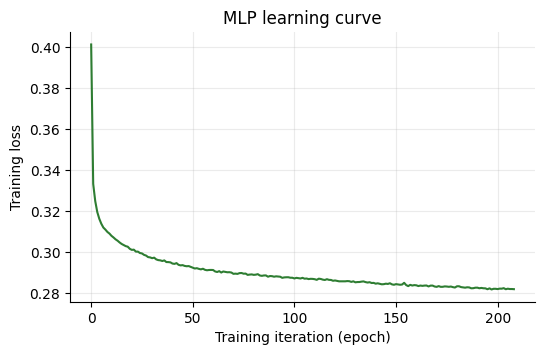

Iterations run: 209 | final training loss: 0.282


MLP regressor added to the regression table.


In [ ]:
from sklearn.neural_network import MLPClassifier, MLPRegressor

mlp = add_clf("Neural Network (MLP)", scaled(MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=300, random_state=42)))
loss = mlp.named_steps["model"].loss_curve_
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(loss, color=GREEN); ax.set_xlabel("Training iteration (epoch)"); ax.set_ylabel("Training loss"); ax.set_title("MLP learning curve")
plt.show()
print("Iterations run:", len(loss), "| final training loss:", round(loss[-1], 4))

add_reg("Neural Network (MLP) regression", scaled(MLPRegressor(hidden_layer_sizes=(32, 16), max_iter=300, random_state=42)), features)
print("MLP regressor added to the regression table.")

---
# Part 11 · Model performance, ensembles and improving accuracy *(Practical 10, Unit VI, CO6)*

### 11A · Bias–variance trade-off
- **High bias (underfitting):** the model is too simple and is poor even on the training data.
- **High variance (overfitting):** the model memorises the training data and does worse on new data.

We show this with a decision tree whose depth we increase from 1 to 20.

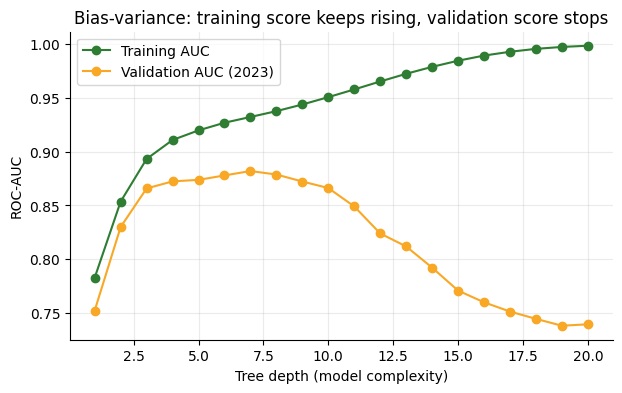

Best validation AUC at depth 7. Beyond that the tree memorises noise (overfitting).


In [ ]:
depths = list(range(1, 21))
tr_auc, va_auc = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(train[features], train.target_fire)
    tr_auc.append(M.roc_auc_score(train.target_fire, t.predict_proba(train[features])[:, 1]))
    va_auc.append(M.roc_auc_score(val.target_fire, t.predict_proba(val[features])[:, 1]))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(depths, tr_auc, marker="o", label="Training AUC", color=GREEN)
ax.plot(depths, va_auc, marker="o", label="Validation AUC (2023)", color=AMBER)
ax.set_xlabel("Tree depth (model complexity)"); ax.set_ylabel("ROC-AUC"); ax.legend()
ax.set_title("Bias-variance: training score keeps rising, validation score stops")
plt.show()
best_depth = depths[int(np.argmax(va_auc))]
print(f"Best validation AUC at depth {best_depth}. Beyond that the tree memorises noise (overfitting).")

### 11B · Ensemble learning: Bagging, Random Forest, Boosting
- **Bagging:** train many models on random resamples of the data and average them (reduces variance).
- **Random Forest:** bagging of decision trees, with random feature choice at every split.
- **Boosting:** train models one after another, each one correcting the previous mistakes (reduces bias). We use scikit-learn's `HistGradientBoosting`.

Ensembles trained.


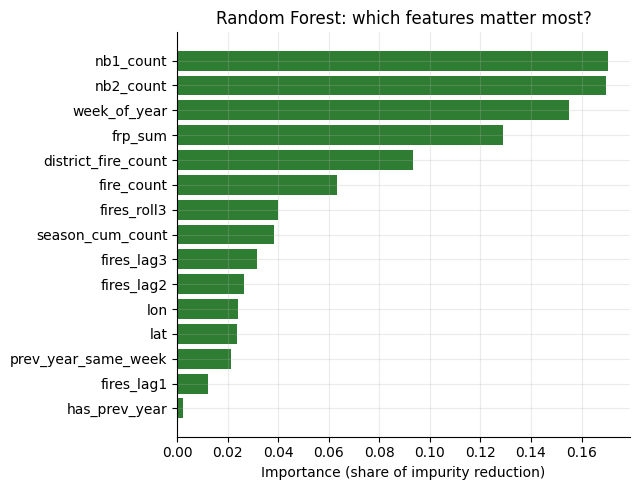

Top 5: {'nb1_count': 0.171, 'nb2_count': 0.17, 'week_of_year': 0.155, 'frp_sum': 0.129, 'district_fire_count': 0.093}


In [ ]:
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, HistGradientBoostingClassifier,
                              RandomForestRegressor, HistGradientBoostingRegressor)
from sklearn.tree import DecisionTreeRegressor

bag = add_clf("Bagging (30 trees)", BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=8, min_samples_leaf=50),
                                                        n_estimators=30, n_jobs=-1, random_state=42))
rf = add_clf("Random Forest", RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20, n_jobs=-1, random_state=42))
boost = add_clf("Boosting (HistGradientBoosting)", HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, max_depth=6,
                                                                                 early_stopping=False, random_state=42))

add_reg("Decision Tree Regressor", DecisionTreeRegressor(max_depth=8, min_samples_leaf=50, random_state=42), features)
rf_reg = add_reg("Random Forest Regressor", RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=20, n_jobs=-1, random_state=42), features)
add_reg("Boosting Regressor (HistGradientBoosting)", HistGradientBoostingRegressor(max_iter=200, learning_rate=0.08, max_depth=6, early_stopping=False, random_state=42), features)
print("Ensembles trained.")

imp = pd.Series(rf.feature_importances_, index=features).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.barh(imp.index, imp.values, color=GREEN); ax.set_xlabel("Importance (share of impurity reduction)")
ax.set_title("Random Forest: which features matter most?"); plt.tight_layout(); plt.show()
print("Top 5:", imp.sort_values(ascending=False).head(5).round(3).to_dict())

### 11C · Improving accuracy (CO6): two methods, measured honestly
Because the test years look very different from the training years, we try two standard improvements and **measure** whether they help:

1. **Threshold tuning:** a classifier says "fire" when its score is above 0.5 by default. When fires become rarer, 0.5 is not the best cut-off. We choose the best cut-off **on the validation year only** and then apply it to the test years.
2. **Retraining on more recent data:** after choosing a model on the validation year, refit it on 2020–2023 (train + validation) so it has seen conditions closer to the test years.

In [ ]:
# pick the best classifier using the VALIDATION year only (highest PR-AUC), excluding baselines
cands = clf_table_tmp = pd.DataFrame(clf_rows)
cands = cands[~cands.Model.str.startswith("Baseline")]
best_name = cands.sort_values("Val PR-AUC", ascending=False).iloc[0]["Model"]
print("Best classifier on validation (PR-AUC):", best_name)

sv, st = clf_scores[best_name]
cuts = np.unique(np.quantile(sv, np.linspace(0.02, 0.98, 97)))
f1s = [M.f1_score(val.target_fire, (sv >= c).astype(int)) for c in cuts]
cut = float(cuts[int(np.argmax(f1s))])
pt_default = (st >= 0.5).astype(int) if best_name != "SVM (RBF kernel)" else (st > 0).astype(int)
pt_tuned = (st >= cut).astype(int)
print(f"Tuned threshold (chosen on 2023): {cut:.3f}")

rows = []
for label, p in [("default threshold", pt_default), ("tuned threshold", pt_tuned)]:
    rows.append({"Version": f"{best_name} - {label}", "Precision": M.precision_score(test.target_fire, p, zero_division=0),
                 "Recall": M.recall_score(test.target_fire, p, zero_division=0), "F1": M.f1_score(test.target_fire, p, zero_division=0)})

# refit the same kind of model on 2020-2023
factories = {
    "Logistic Regression": lambda: scaled(LogisticRegression(max_iter=2000)),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20, n_jobs=-1, random_state=42),
    "Boosting (HistGradientBoosting)": lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, max_depth=6, early_stopping=False, random_state=42),
    "Bagging (30 trees)": lambda: BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=8, min_samples_leaf=50), n_estimators=30, n_jobs=-1, random_state=42),
    "Neural Network (MLP)": lambda: scaled(MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=300, random_state=42)),
    "Decision Tree": lambda: DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=42),
    "Naive Bayes (Gaussian)": lambda: scaled(GaussianNB()),
}
if best_name in factories:
    recent = pd.concat([train, val])
    refit = factories[best_name]().fit(recent[features], recent.target_fire)
    s_refit = refit.predict_proba(test[features])[:, 1]
    p_refit = (s_refit >= 0.5).astype(int)
    rows.append({"Version": f"{best_name} - refit on 2020-2023", "Precision": M.precision_score(test.target_fire, p_refit, zero_division=0),
                 "Recall": M.recall_score(test.target_fire, p_refit, zero_division=0), "F1": M.f1_score(test.target_fire, p_refit, zero_division=0)})
    rows.append({"Version": f"{best_name} - refit on 2020-2023 (ROC-AUC {M.roc_auc_score(test.target_fire, s_refit):.3f})",
                 "Precision": np.nan, "Recall": np.nan, "F1": np.nan})
else:
    print("(Refit experiment is defined for the models in the 'factories' list; best model was:", best_name, ")")
improve = pd.DataFrame(rows)
improve.style.format({"Precision": "{:.3f}", "Recall": "{:.3f}", "F1": "{:.3f}"}, na_rep="")

Best classifier on validation (PR-AUC): Boosting (HistGradientBoosting)


Tuned threshold (chosen on 2023): 0.390


,Version,Precision,Recall,F1
0,Boosting (HistGradientBoosting) - default threshold,0.468,0.351,0.401
1,Boosting (HistGradientBoosting) - tuned threshold,0.426,0.423,0.424
2,Boosting (HistGradientBoosting) - refit on 2020-2023,0.502,0.421,0.458
3,Boosting (HistGradientBoosting) - refit on 2020-2023 (ROC-AUC 0.842),,,


In [ ]:
# the same idea for regression: refit the Random Forest regressor on 2020-2023 and test on 2024-2025
recent = pd.concat([train, val])
rf_reg2 = RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=20, n_jobs=-1, random_state=42).fit(recent[features], recent.target_count)
before = reg_scores(test.target_count, reg_preds["Random Forest Regressor"])
after = reg_scores(test.target_count, rf_reg2.predict(test[features]))
print(pd.DataFrame({"RF regressor trained on 2020-22": before, "RF regressor refit on 2020-23": after}).round(3))

      RF regressor trained on 2020-22  RF regressor refit on 2020-23
MAE                             0.519                          0.486
MSE                             1.433                          1.139
RMSE                            1.197                          1.067
R2                             -0.751                         -0.392


---
# Part 12 · Final comparison, conclusions and limitations

In [ ]:
os.makedirs("reports", exist_ok=True)
clf_table = pd.DataFrame(clf_rows)
reg_table = pd.DataFrame(reg_rows)
clf_table.to_csv("reports/classification_results.csv", index=False)
reg_table.to_csv("reports/regression_results.csv", index=False)

print("=== CLASSIFICATION: test period 2024-2025 (sorted by ROC-AUC) ===")
cols = ["Model", "Test Accuracy", "Test Precision", "Test Recall", "Test F1", "Test ROC-AUC", "Test PR-AUC", "Test LogLoss"]
display(clf_table[cols].sort_values("Test ROC-AUC", ascending=False).style.format({c: "{:.3f}" for c in cols if c != "Model"}, na_rep="-"))

print("\n=== REGRESSION: test period 2024-2025 (sorted by RMSE) ===")
cols = ["Model", "Test MAE", "Test RMSE", "Test R2", "Val MAE", "Val RMSE", "Val R2"]
display(reg_table[cols].sort_values("Test RMSE").style.format({c: "{:.3f}" for c in cols if c != "Model"}))

=== CLASSIFICATION: test period 2024-2025 (sorted by ROC-AUC) ===


,Model,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,Test PR-AUC,Test LogLoss
11,Random Forest,0.856,0.498,0.312,0.384,0.838,0.450,0.325
4,Naive Bayes (Gaussian),0.855,0.495,0.331,0.397,0.834,0.440,0.800
7,SVM (RBF kernel),0.846,0.470,0.540,0.503,0.832,0.461,-
5,KNN (k=15),0.820,0.417,0.639,0.505,0.825,0.427,0.619
8,Logistic Regression on 6 PCA components,0.851,0.479,0.391,0.431,0.824,0.441,0.347
3,Logistic Regression,0.859,0.514,0.319,0.393,0.812,0.440,0.335
12,Boosting (HistGradientBoosting),0.849,0.468,0.351,0.401,0.807,0.420,0.352
9,Neural Network (MLP),0.820,0.389,0.437,0.412,0.802,0.390,0.411
10,Bagging (30 trees),0.853,0.481,0.302,0.371,0.782,0.401,0.358
6,Decision Tree,0.846,0.449,0.322,0.376,0.757,0.369,0.386



=== REGRESSION: test period 2024-2025 (sorted by RMSE) ===


,Model,Test MAE,Test RMSE,Test R2,Val MAE,Val RMSE,Val R2
0,Baseline: same as this week,0.401,1.098,-0.474,1.540,3.694,-0.143
9,Random Forest Regressor,0.519,1.197,-0.751,1.448,3.422,0.019
10,Boosting Regressor (HistGradientBoosting),0.600,1.215,-0.802,1.542,3.445,0.006
8,Decision Tree Regressor,0.512,1.273,-0.980,1.634,4.005,-0.344
5,Polynomial Regression (degree 2),0.814,1.658,-2.360,1.891,3.770,-0.191
3,Simple Linear Regression,1.621,1.722,-2.621,2.237,3.257,0.111
2,Baseline: same week last year,0.850,2.498,-6.623,1.494,3.718,-0.158
7,Neural Network (MLP) regression,1.227,2.553,-6.966,1.638,3.590,-0.080
6,Ridge Regression,1.662,2.581,-7.141,2.435,3.783,-0.199
4,Multiple Linear Regression,1.663,2.584,-7.155,2.436,3.785,-0.200


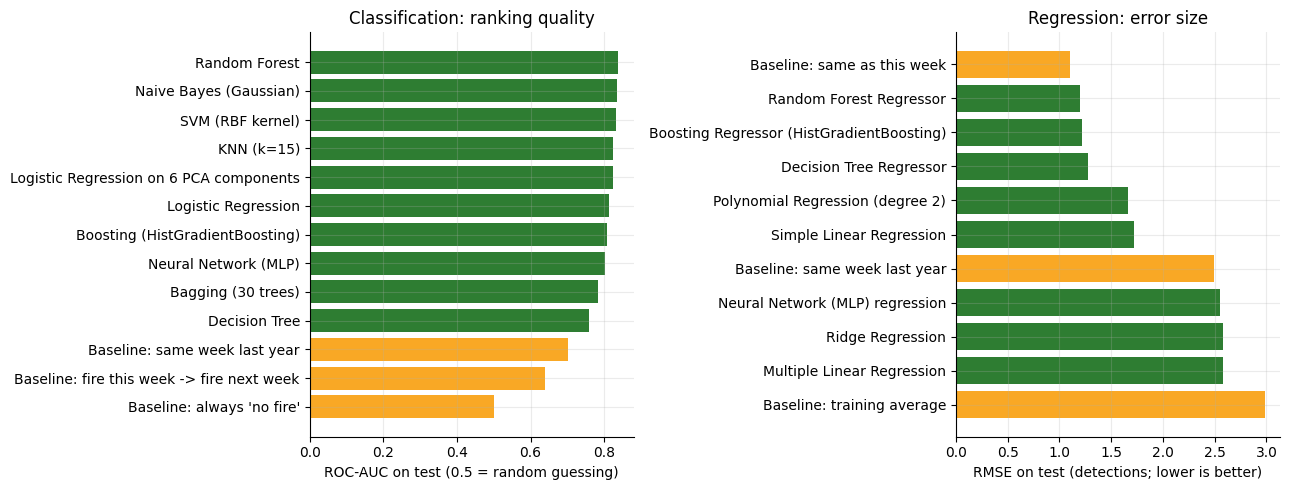

In [ ]:
# charts for the report
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
c = clf_table.sort_values("Test ROC-AUC")
axs[0].barh(c.Model, c["Test ROC-AUC"], color=[AMBER if m.startswith("Baseline") else GREEN for m in c.Model])
axs[0].set_xlabel("ROC-AUC on test (0.5 = random guessing)"); axs[0].set_title("Classification: ranking quality")
r = reg_table.sort_values("Test RMSE", ascending=False)
axs[1].barh(r.Model, r["Test RMSE"], color=[AMBER if m.startswith("Baseline") else GREEN for m in r.Model])
axs[1].set_xlabel("RMSE on test (detections; lower is better)"); axs[1].set_title("Regression: error size")
plt.tight_layout(); plt.savefig("reports/final_comparison.png", dpi=130); plt.show()

In [ ]:
# written conclusions generated from the REAL numbers above
cl = clf_table[~clf_table.Model.str.startswith("Baseline")]
base_cl = clf_table[clf_table.Model.str.startswith("Baseline")]
top = cl.sort_values("Test ROC-AUC", ascending=False).iloc[0]
persist = base_cl[base_cl.Model.str.contains("this week")].iloc[0]
best_f1 = cl.sort_values("Test F1", ascending=False).iloc[0]
rg = reg_table[~reg_table.Model.str.startswith("Baseline")]
base_rg = reg_table[reg_table.Model.str.startswith("Baseline")]
best_rmse = rg.sort_values("Test RMSE").iloc[0]
best_base = base_rg.sort_values("Test RMSE").iloc[0]

print("KEY FINDINGS (computed from this run)")
print("-" * 70)
print(f"1. Share of cell-weeks with a detection next week fell from {data[data.year==2020].target_fire.mean():.0%} in 2020 "
      f"to {data[data.year==2025].target_fire.mean():.0%} in 2025.")
print(f"2. Classification: best ranking on the test years was {top.Model} (ROC-AUC {top['Test ROC-AUC']:.3f}); "
      f"the 'fire this week -> fire next week' rule reached {persist['Test ROC-AUC']:.3f}.")
print(f"3. Best F1 on test: {best_f1.Model} (F1 {best_f1['Test F1']:.3f}, precision {best_f1['Test Precision']:.3f}, recall {best_f1['Test Recall']:.3f}).")
print(f"4. Regression: lowest test RMSE among models was {best_rmse.Model} ({best_rmse['Test RMSE']:.3f}); "
      f"best baseline was {best_base.Model} ({best_base['Test RMSE']:.3f}).")
better = best_rmse["Test RMSE"] < best_base["Test RMSE"]
print(f"   -> the best regression model {'beats' if better else 'does NOT beat'} the best simple baseline on RMSE.")
print(f"5. Number of test-period R2 values below zero among regression models: {int((rg['Test R2'] < 0).sum())} of {len(rg)}.")
print(f"6. Retraining the Random Forest regressor on 2020-2023 changed test RMSE from {before['RMSE']:.3f} to {after['RMSE']:.3f} "
      f"(best baseline: {best_base['Test RMSE']:.3f}) -> it {'beats' if after['RMSE'] < best_base['Test RMSE'] else 'still does not beat'} the baseline on RMSE.")
print("-" * 70)

KEY FINDINGS (computed from this run)
----------------------------------------------------------------------
1. Share of cell-weeks with a detection next week fell from 41% in 2020 to 10% in 2025.
2. Classification: best ranking on the test years was Random Forest (ROC-AUC 0.838); the 'fire this week -> fire next week' rule reached 0.640.
3. Best F1 on test: KNN (k=15) (F1 0.505, precision 0.417, recall 0.639).
4. Regression: lowest test RMSE among models was Random Forest Regressor (1.197); best baseline was Baseline: same as this week (1.098).
   -> the best regression model does NOT beat the best simple baseline on RMSE.
5. Number of test-period R2 values below zero among regression models: 8 of 8.
6. Retraining the Random Forest regressor on 2020-2023 changed test RMSE from 1.197 to 1.067 (best baseline: 1.098) -> it beats the baseline on RMSE.
----------------------------------------------------------------------


## Conclusions (how to read the results above)

1. **The problem is predictable in a ranking sense.** Models separate cells likely to burn next week from cells unlikely to burn clearly better than chance (ROC-AUC well above 0.5). Past activity in the cell and its neighbours is the strongest signal (see Random Forest importance).
2. **Predicting the exact count is much harder** than predicting yes/no, especially because counts fell sharply in 2024–2025. Always compare against the simple baselines, as done here, before claiming a model is useful.
3. **Distribution shift matters.** Models trained on 2020–2022 face a different situation in 2024–2025. Threshold tuning and retraining on recent years are standard ways to adapt; their measured effect is shown in Part 11C.
4. **Unsupervised learning** grouped cells and districts into behaviour types, and association rules showed which districts tend to be very active on the same days.

## Limitations (say these in the viva)
- NASA detections are **satellite thermal anomalies**, not confirmed stubble-burning incidents.
- The satellite sees an area only a few times a day; clouds and overpass time can hide fires. A zero means "no detection", not "no fire". The satellite's overpass time has also changed over the years, which may affect counts.
- Only **six seasons** of data; test = two seasons. Results could change with more years.
- The district map is a third-party file (22 districts), not an official survey boundary; 5 km cells are coarse; detections in border cells whose centre is outside Punjab are dropped.
- Weather comes from district-centre points and approximates local conditions. **If you ran this notebook without internet, the models are fire-only and weather is pending.**
- SVM was trained on a 6,000-row sample for speed; KNN's k was chosen on a validation sample.

## Future scope
- Add NOAA-20 / NOAA-21 VIIRS detections and weather (if not already included).
- Retrain on a rolling window of the most recent seasons; calibrate probabilities.
- Add crop-area, soil-moisture and harvest-date data.
- Build a Streamlit dashboard for officials (a starter version is in `advanced_version/`).

## Project links *(fill these in before submitting the report)*

| Item | Link |
|---|---|
| Project (GitHub repository) | `PASTE YOUR GITHUB LINK` |
| Dataset (final weekly grid dataset: Kaggle / Google Drive) | `PASTE YOUR DATASET LINK` |
| LinkedIn post | `PASTE YOUR LINKEDIN POST LINK` |
| Original data: NASA FIRMS | https://firms.modaps.eosdis.nasa.gov/ |
| Original weather data: Open-Meteo | https://open-meteo.com/en/docs/historical-weather-api |

## References
- NASA FIRMS (Fire Information for Resource Management System), VIIRS S-NPP active fire data: https://firms.modaps.eosdis.nasa.gov/
- Open-Meteo Historical Weather API: https://open-meteo.com/
- Punjab district boundaries: https://github.com/udit-001/india-maps-data
- Müller, A. C. & Guido, S. *Introduction to Machine Learning with Python*, O'Reilly (INT234 text book)
- Géron, A. *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*, 3rd ed., O'Reilly (INT234 reference)
- scikit-learn documentation: https://scikit-learn.org/

## Viva cheat-sheet (short answers)

**Why this problem?** Stubble burning harms air quality and health in Punjab every autumn, and free satellite data exists, so a data-driven early warning is realistic.

**What exactly do you predict?** For each 5 km cell, whether the satellite will detect at least one fire next week (classification) and how many detections (regression).

**Where does the data come from?** NASA FIRMS VIIRS S-NPP archive (2020–2025) for a box around Punjab, cleaned and filtered to Punjab districts. Weather from Open-Meteo when available.

**Why a time-based split?** Random splitting would let the model see future weeks while training, which gives falsely good scores.

**What is leakage and how did you avoid it?** Using future information in the inputs. Every feature uses only this week or earlier; next week is used only as the label; scaling is fitted on training rows only.

**Why is accuracy misleading here?** Most cell-weeks have no fire, so "always no fire" already scores high. We use precision, recall, F1 and AUC.

**Which model is best?** Say what the final tables in Part 12 show for classification and regression, and mention the baselines and the distribution shift.

**What is the bias–variance trade-off?** Simple models underfit (high bias); very flexible models overfit (high variance). Part 11A shows it with tree depth.

**What did clustering add?** It grouped cells and districts by behaviour over the years, which describes hotspots; it is not a forecast.

**Biggest limitation?** Detections are satellite signals, not confirmed stubble burning, and detections dropped sharply over the years, which makes later years different from the training years.